# **Integrated Data Mining Framework for Analyzing Provincial Disease Mortality Patterns in Indonesia Using FP-Growth Association Rules, K-Means and DBSCAN Clustering, and Ensemble Regression Models (Random Forest, XGBoost, CatBoost, and LightGBM) with SHAP Interpretability (2018–2023)**

**Member of The Group:**

**- Abdullah Al-Firdaus Nuzula (24031554008)**

**- Faishal Muflih Irfanu Tsaqib (24031554170)**

**- Elvira Tiara Suci Tambunan (24031554213)**


Link Asset: https://drive.google.com/drive/folders/1sami7mIXZd5PUgCXqSuEN81wmP823Hsg


In [98]:
!pip install -q mlxtend mapclassify catboost

In [99]:
import os, sys, io, warnings, logging

os.environ['PYTHONWARNINGS'] = 'ignore'
warnings.filterwarnings('ignore')
logging.captureWarnings(True)
logging.getLogger('py.warnings').setLevel(logging.CRITICAL)
logging.getLogger('jupyter_client').setLevel(logging.CRITICAL)
logging.getLogger('tornado').setLevel(logging.CRITICAL)

_stderr = sys.stderr
sys.stderr = io.StringIO()

import pandas as pd
import numpy as np
import time
import gdown
import zipfile
import urllib.request
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import seaborn as sns
import networkx as nx
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import RobustScaler

from mlxtend.frequent_patterns import fpgrowth, apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (silhouette_score, silhouette_samples,
                              davies_bouldin_score, r2_score,
                              mean_absolute_error, mean_squared_error)
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate

import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import shap

sys.stderr = _stderr

sns.set_style("whitegrid")
plt.rcParams['figure.dpi']    = 120
plt.rcParams['savefig.dpi']   = 150

## **Load Data**

In [100]:
FILE_ID = "1OK-llZZl3zy68oIukMRr9x11-akedQwB"
URL = f"https://drive.google.com/uc?id={FILE_ID}"
OUTPUT_PATH = "/content/master_panel_raw.csv"

gdown.download(URL, OUTPUT_PATH, quiet=False)
df_raw = pd.read_csv(OUTPUT_PATH, sep=';')

print(f"Shape: {df_raw.shape[0]} baris × {df_raw.shape[1]} kolom")
print(f"\nKolom yang tersedia:")
print(df_raw.columns.tolist())

Downloading...
From: https://drive.google.com/uc?id=1OK-llZZl3zy68oIukMRr9x11-akedQwB
To: /content/master_panel_raw.csv
100%|██████████| 25.2k/25.2k [00:00<00:00, 12.7MB/s]

Shape: 234 baris × 16 kolom

Kolom yang tersedia:
['provinsi', 'tahun', 'pulau', 'kemiskinan_pct', 'rata_lama_sekolah', 'akses_air_bersih_pct', 'sanitasi_layak_pct', 'jumlah_rs_per_100k', 'jumlah_pkm_per_100k', 'rasio_dokter_per_100k', 'kepadatan_penduduk', 'jumlah_penduduk', 'mortalitas_pneumonia', 'mortalitas_dbd', 'mortalitas_tbc', 'mortality_composite']


## **1. Exploratory Data Analysis Simple**

In [101]:
print("General Information Dataset")
df_raw.info()

print("First 5 Rows")
display(df_raw.head())

print("Unique Province Name (before cleaning)")

provinces_raw = df_raw['provinsi'].unique()
print(f"Total provinsi unik: {len(provinces_raw)}")
for i, prov in enumerate(provinces_raw, 1):
    print(f"  {i:2}. {prov}")

print("Checking Missing Value")
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
display(missing_df[missing_df['missing_count'] > 0])

General Information Dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   provinsi               234 non-null    object 
 1   tahun                  234 non-null    int64  
 2   pulau                  204 non-null    object 
 3   kemiskinan_pct         210 non-null    float64
 4   rata_lama_sekolah      234 non-null    object 
 5   akses_air_bersih_pct   204 non-null    float64
 6   sanitasi_layak_pct     204 non-null    float64
 7   jumlah_rs_per_100k     204 non-null    float64
 8   jumlah_pkm_per_100k    204 non-null    float64
 9   rasio_dokter_per_100k  204 non-null    float64
 10  kepadatan_penduduk     210 non-null    float64
 11  jumlah_penduduk        210 non-null    float64
 12  mortalitas_pneumonia   204 non-null    float64
 13  mortalitas_dbd         204 non-null    float64
 14  mortalitas_tbc         204 non

,provinsi,tahun,pulau,kemiskinan_pct,rata_lama_sekolah,akses_air_bersih_pct,sanitasi_layak_pct,jumlah_rs_per_100k,jumlah_pkm_per_100k,rasio_dokter_per_100k,kepadatan_penduduk,jumlah_penduduk,mortalitas_pneumonia,mortalitas_dbd,mortalitas_tbc,mortality_composite
0,ACEH,2018,Sumatera,15.97,9.46,66.48,67.09,1.2686,6.7218,40.2174,91.0,5281300.0,0.4734,0.1325,2.3479,0.121889
1,ACEH,2019,Sumatera,15.32,9.59,85.81,73.16,1.2846,6.6834,41.1989,93.0,5371500.0,0.4096,0.1117,2.2154,0.105387
2,ACEH,2020,Sumatera,14.99,9.71,87.66,77.06,1.3270,6.8058,45.6502,91.0,5274900.0,0.5687,0.0190,3.0143,0.128577
3,ACEH,2021,Sumatera,15.33,9.77,88.79,77.55,1.3499,6.7495,49.0091,92.0,5333700.0,0.5625,0.1312,4.6684,0.146455
4,ACEH,2022,Sumatera,14.64,9.79,89.70,77.48,1.3499,6.6939,52.1459,95.0,5407900.0,0.4623,0.2959,4.9742,0.148055


Unique Province Name (before cleaning)
Total provinsi unik: 39
   1. ACEH
   2. BALI
   3. BANGKA BELITUNG
   4. BANTEN
   5. BENGKULU
   6. DI YOGYAKARTA
   7. DKI JAKARTA
   8. GORONTALO
   9. INDONESIA
  10. JAMBI
  11. JAWA BARAT
  12. JAWA TENGAH
  13. JAWA TIMUR
  14. KALIMANTAN BARAT
  15. KALIMANTAN SELATAN
  16. KALIMANTAN TENGAH
  17. KALIMANTAN TIMUR
  18. KALIMANTAN UTARA
  19. KEPULAUAN RIAU
  20. LAMPUNG
  21. MALUKU
  22. MALUKU UTARA
  23. NUSA TENGGARA BARAT
  24. NUSA TENGGARA TIMUR
  25. PAPUA
  26. PAPUA BARAT
  27. PAPUA BARAT DAYA
  28. PAPUA PEGUNUNGAN
  29. PAPUA SELATAN
  30. PAPUA TENGAH
  31. RIAU
  32. SULAWESI BARAT
  33. SULAWESI SELATAN
  34. SULAWESI TENGAH
  35. SULAWESI TENGGARA
  36. SULAWESI UTARA
  37. SUMATERA BARAT
  38. SUMATERA SELATAN
  39. SUMATERA UTARA
Checking Missing Value


,missing_count,missing_pct
pulau,30,12.82
kemiskinan_pct,24,10.26
akses_air_bersih_pct,30,12.82
sanitasi_layak_pct,30,12.82
jumlah_rs_per_100k,30,12.82
jumlah_pkm_per_100k,30,12.82
rasio_dokter_per_100k,30,12.82
kepadatan_penduduk,24,10.26
jumlah_penduduk,24,10.26
mortalitas_pneumonia,30,12.82


## **2. Preprocessing**

### a. Drop Kolom yang tak perlu

In [102]:
PROVINCES_TO_DROP = [
    'INDONESIA',
    'PAPUA BARAT DAYA',
    'PAPUA PEGUNUNGAN',
    'PAPUA SELATAN',
    'PAPUA TENGAH',
]

df = df_raw[~df_raw['provinsi'].isin(PROVINCES_TO_DROP)].copy()
df = df.sort_values(['tahun', 'provinsi']).reset_index(drop=True)

print(f" Sebelum cleaning : {df_raw.shape[0]} baris")
print(f" Setelah cleaning : {df.shape[0]} baris")
print(f" Baris terhapus   : {df_raw.shape[0] - df.shape[0]} baris")

n_prov = df['provinsi'].nunique()
n_year = df['tahun'].nunique()
expected = n_prov * n_year

print(f"\n Validasi struktur panel:")
print(f"   Jumlah provinsi unik : {n_prov}")
print(f"   Jumlah tahun unik    : {n_year}")
print(f"   Expected (prov × th) : {expected}")
print(f"   Actual rows          : {df.shape[0]}")
print(f"   Status               : {'MATCH' if df.shape[0] == expected else ' MISMATCH'}")

print(f"\n Validasi urutan sort:")
print(f"   Baris 1-3   : {df.iloc[0]['provinsi']} {df.iloc[0]['tahun']}, "
      f"{df.iloc[1]['provinsi']} {df.iloc[1]['tahun']}, "
      f"{df.iloc[2]['provinsi']} {df.iloc[2]['tahun']}")
print(f"   Baris 34-36 : {df.iloc[33]['provinsi']} {df.iloc[33]['tahun']}, "
      f"{df.iloc[34]['provinsi']} {df.iloc[34]['tahun']}, "
      f"{df.iloc[35]['provinsi']} {df.iloc[35]['tahun']}")
print(f"   Baris 202-204: {df.iloc[201]['provinsi']} {df.iloc[201]['tahun']}, "
      f"{df.iloc[202]['provinsi']} {df.iloc[202]['tahun']}, "
      f"{df.iloc[203]['provinsi']} {df.iloc[203]['tahun']}")

prov_2018 = df[df['tahun']==2018]['provinsi'].tolist()
prov_2023 = df[df['tahun']==2023]['provinsi'].tolist()
print(f"   Urutan provinsi 2018 == 2023: {'konsisten' if prov_2018 == prov_2023 else ' inkonsisten'}")

 Sebelum cleaning : 234 baris
 Setelah cleaning : 204 baris
 Baris terhapus   : 30 baris

 Validasi struktur panel:
   Jumlah provinsi unik : 34
   Jumlah tahun unik    : 6
   Expected (prov × th) : 204
   Actual rows          : 204
   Status               : MATCH

 Validasi urutan sort:
   Baris 1-3   : ACEH 2018, BALI 2018, BANGKA BELITUNG 2018
   Baris 34-36 : SUMATERA UTARA 2018, ACEH 2019, BALI 2019
   Baris 202-204: SUMATERA BARAT 2023, SUMATERA SELATAN 2023, SUMATERA UTARA 2023
   Urutan provinsi 2018 == 2023: konsisten


### b. Konversi Tipe Data to Float

In [103]:
NUMERIC_COLS = [
    'kemiskinan_pct', 'rata_lama_sekolah', 'akses_air_bersih_pct',
    'sanitasi_layak_pct', 'jumlah_rs_per_100k', 'jumlah_pkm_per_100k',
    'rasio_dokter_per_100k', 'kepadatan_penduduk', 'jumlah_penduduk',
    'mortalitas_pneumonia', 'mortalitas_dbd', 'mortalitas_tbc',
    'mortality_composite'
]

for col in NUMERIC_COLS:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['tahun'] = df['tahun'].astype(int)

print(" Konversi tipe data selesai")
print("\nTipe data tiap kolom:")
print(df.dtypes)

print("Descriptive Statistics (kolom numerik)")
display(df[NUMERIC_COLS].describe().round(3).T)

 Konversi tipe data selesai

Tipe data tiap kolom:
provinsi                  object
tahun                      int64
pulau                     object
kemiskinan_pct           float64
rata_lama_sekolah        float64
akses_air_bersih_pct     float64
sanitasi_layak_pct       float64
jumlah_rs_per_100k       float64
jumlah_pkm_per_100k      float64
rasio_dokter_per_100k    float64
kepadatan_penduduk       float64
jumlah_penduduk          float64
mortalitas_pneumonia     float64
mortalitas_dbd           float64
mortalitas_tbc           float64
mortality_composite      float64
dtype: object
Descriptive Statistics (kolom numerik)


,count,mean,std,min,25%,50%,75%,max
kemiskinan_pct,204.0,10.464,5.398000e+00,3.470,6.442,8.735,13.035,2.774000e+01
rata_lama_sekolah,204.0,9.090,8.430000e-01,6.660,8.480,9.095,9.630,1.142000e+01
akses_air_bersih_pct,204.0,84.182,1.020100e+01,49.370,77.570,86.780,92.218,9.986000e+01
sanitasi_layak_pct,204.0,78.339,1.140500e+01,33.750,74.002,79.585,84.580,9.712000e+01
jumlah_rs_per_100k,204.0,1.326,3.750000e-01,0.718,1.014,1.275,1.610,2.317000e+00
jumlah_pkm_per_100k,204.0,5.973,3.196000e+00,0.412,3.457,5.058,7.683,1.674700e+01
rasio_dokter_per_100k,204.0,37.782,1.959900e+01,10.999,25.527,31.792,43.438,1.162550e+02
kepadatan_penduduk,204.0,744.000,2.687175e+03,9.000,49.000,102.000,264.750,1.615800e+04
jumlah_penduduk,204.0,7992382.843,1.120559e+07,701800.000,2148575.000,4202500.000,8452625.000,4.986030e+07
mortalitas_pneumonia,204.0,0.435,3.430000e-01,0.000,0.158,0.332,0.551,1.587000e+00


### c. Missing Value Check

In [104]:
print("Missing Value after Converting Type")
missing_after = df[NUMERIC_COLS].isnull().sum()
missing_after = missing_after[missing_after > 0]

if len(missing_after) > 0:
    print(missing_after)

    df = df.sort_values(['tahun', 'provinsi']).reset_index(drop=True)

    for col in missing_after.index:
        df[col] = df.groupby('provinsi')[col].transform(
            lambda x: x.interpolate(method='linear', limit=2, limit_direction='both')
        )

    print("\nAfter Imputation:")
    print(df[NUMERIC_COLS].isnull().sum())
else:
    print("No missing values")

Missing Value after Converting Type
No missing values


### d. Rekalkulasi Mortality Composite

`mortality_composite` dihitung sebagai rata-rata min-max normalized dari ketiga target utama (TBC, Pneumonia, DBD). Variabel ini berfungsi sebagai **indikator deskriptif ringkasan beban penyakit** dan **tidak diikutsertakan dalam pipeline analitik** (FP-Growth, Clustering, maupun Regression), karena merupakan fungsi linear dari ketiga target tersebut. Memasukkannya ke pipeline akan menciptakan multikolinearitas dengan target yang sudah ada.

In [105]:
TARGET_COLS = ['mortalitas_tbc', 'mortalitas_pneumonia', 'mortalitas_dbd']

def min_max_normalize(s):
    return (s - s.min()) / (s.max() - s.min())

df['mortality_composite_OLD'] = df['mortality_composite'].copy()
df_normalized                 = df[TARGET_COLS].apply(min_max_normalize)
df['mortality_composite']     = df_normalized.mean(axis=1)

df = df.drop(columns=['mortality_composite_OLD'])

print("mortality_composite di-recalculate (deskriptif saja, tidak masuk pipeline)")
print(f"  Range: [{df['mortality_composite'].min():.4f}, {df['mortality_composite'].max():.4f}]")
print(f"  Mean : {df['mortality_composite'].mean():.4f}")

top_burden = df.groupby('provinsi')['mortality_composite'].mean()\
               .sort_values(ascending=False).head(5)
print(f"\nTop 5 provinsi beban mortalitas gabungan tertinggi (rata-rata 2018-2023):")
for prov, val in top_burden.items():
    print(f"  {prov:30} : {val:.4f}")

mortality_composite di-recalculate (deskriptif saja, tidak masuk pipeline)
  Range: [0.0224, 0.6195]
  Mean : 0.1699

Top 5 provinsi beban mortalitas gabungan tertinggi (rata-rata 2018-2023):
  KALIMANTAN UTARA               : 0.3990
  NUSA TENGGARA TIMUR            : 0.3774
  GORONTALO                      : 0.3408
  BANGKA BELITUNG                : 0.3234
  KALIMANTAN TIMUR               : 0.2967


### e. Outlier Detection

In [106]:
def detect_outliers_iqr(series, factor=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - factor * iqr
    upper = q3 + factor * iqr
    return (series < lower) | (series > upper)


print("Outlier Detection (IQR method, factor=1.5)")


outlier_summary = []
for col in NUMERIC_COLS:
    if col == 'mortality_composite':
        continue
    mask = detect_outliers_iqr(df[col])
    n_outliers = mask.sum()
    if n_outliers > 0:
        outlier_summary.append({
            'variable': col,
            'n_outliers': n_outliers,
            'pct': round(n_outliers / len(df) * 100, 2)
        })

outlier_df = pd.DataFrame(outlier_summary).sort_values('n_outliers', ascending=False)
print(outlier_df.to_string(index=False))


print("\nTop 10 Outlier Extreme - mortalitas_tbc")

mask_tbc = detect_outliers_iqr(df['mortalitas_tbc'])
top_tbc_outliers = df[mask_tbc].nlargest(10, 'mortalitas_tbc')[
    ['provinsi', 'tahun', 'mortalitas_tbc', 'mortalitas_pneumonia', 'mortalitas_dbd']
]
print(top_tbc_outliers.to_string(index=False))

Outlier Detection (IQR method, factor=1.5)
             variable  n_outliers   pct
   kepadatan_penduduk          42 20.59
      jumlah_penduduk          18  8.82
       mortalitas_dbd          15  7.35
rasio_dokter_per_100k          15  7.35
 mortalitas_pneumonia          14  6.86
   sanitasi_layak_pct          12  5.88
       mortalitas_tbc           9  4.41
       kemiskinan_pct           7  3.43
  jumlah_pkm_per_100k           4  1.96
    rata_lama_sekolah           2  0.98
 akses_air_bersih_pct           1  0.49

Top 10 Outlier Extreme - mortalitas_tbc
         provinsi  tahun  mortalitas_tbc  mortalitas_pneumonia  mortalitas_dbd
  BANGKA BELITUNG   2021        128.8352                0.3394          1.3576
   KEPULAUAN RIAU   2021         80.0680                0.3777          0.8026
 KALIMANTAN UTARA   2021         49.0471                0.4204          0.5605
      PAPUA BARAT   2021         32.4170                0.1729          0.0000
SULAWESI TENGGARA   2021         26.1733 

### g. Analisis Tren Temporal (2018–2023)

Analisis Tren Temporal (2018–2023)


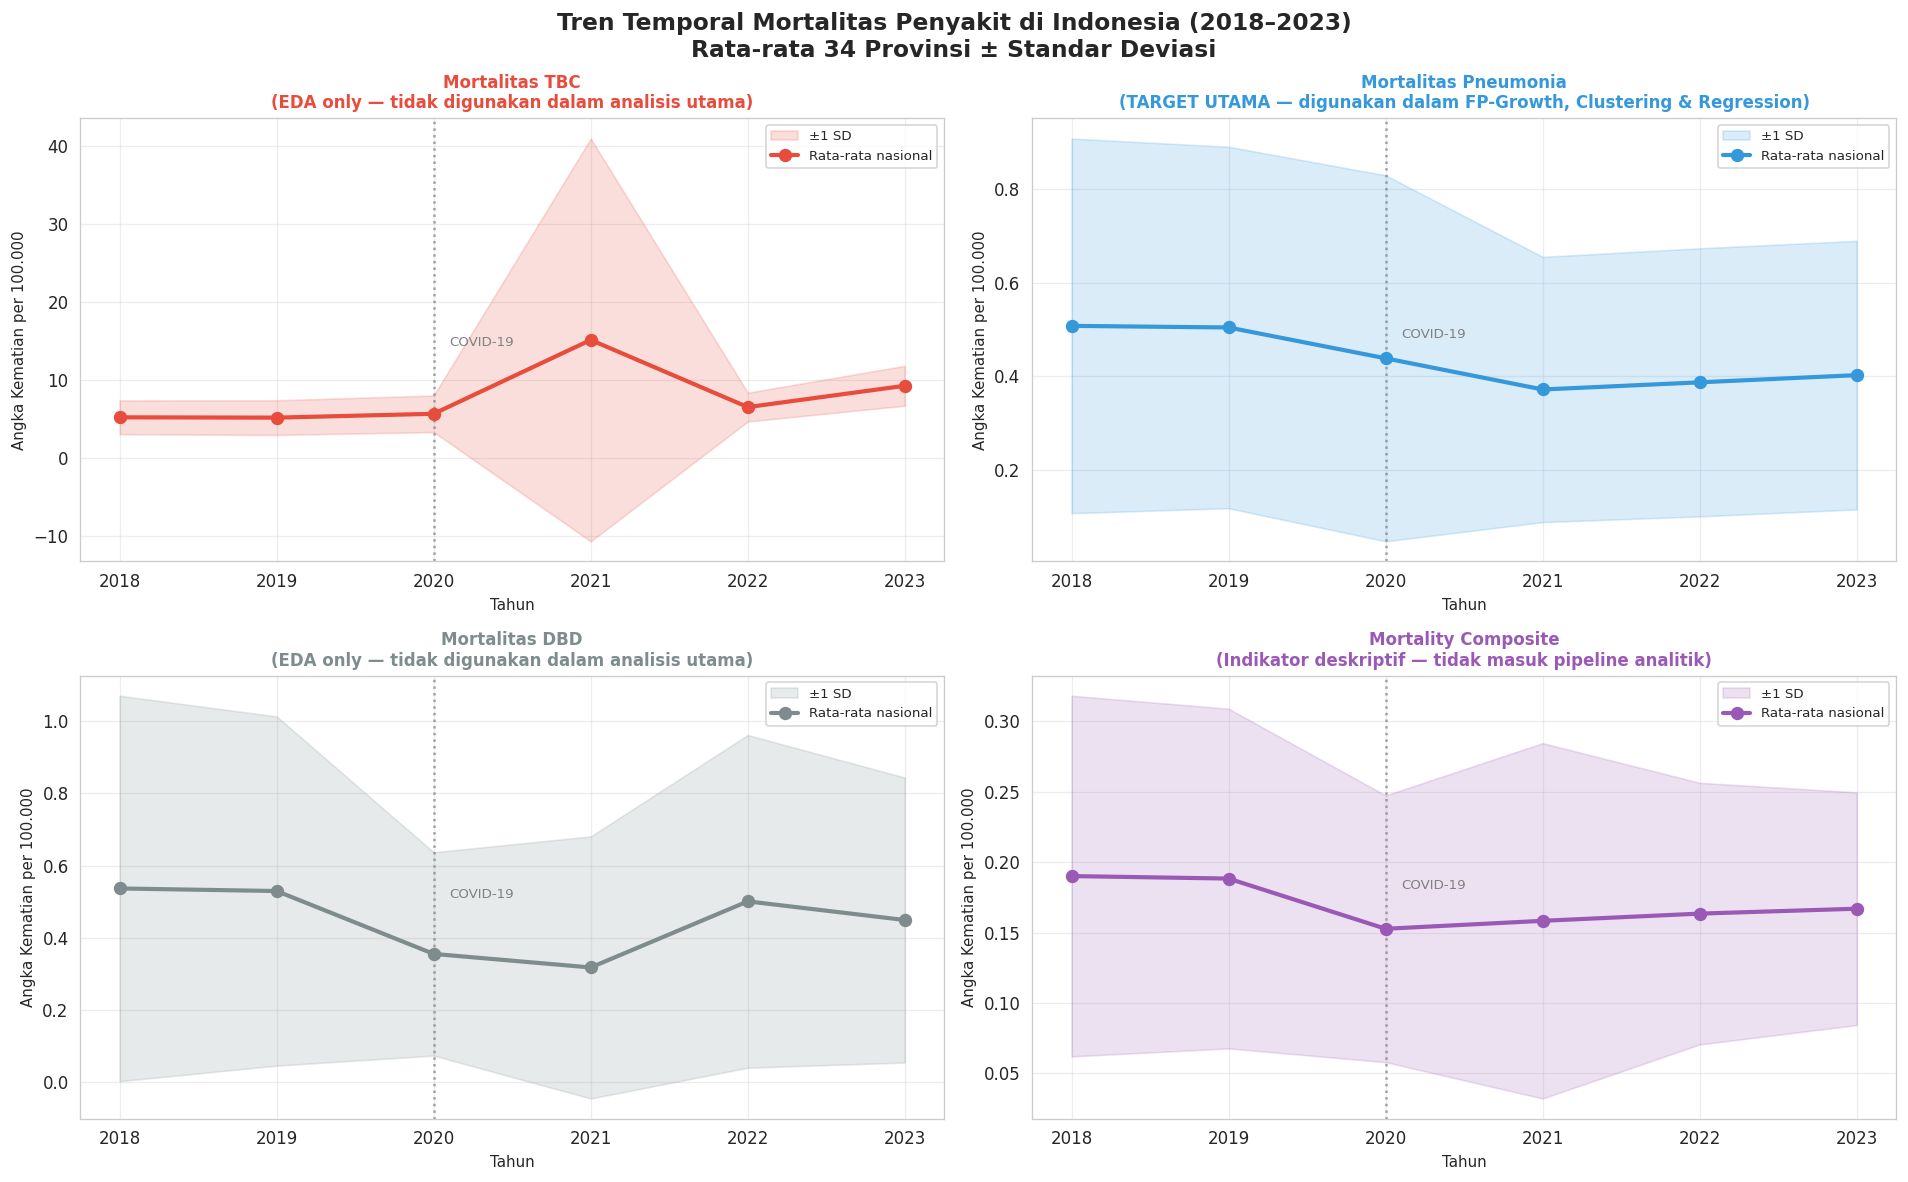

Perubahan kumulatif 2018 → 2023:
  TBC (EDA)                     : 5.1740 → 9.2218  (+78.2%)
  Pneumonia (TARGET)            : 0.5076 → 0.4025  (-20.7%)
  DBD (EDA)                     : 0.5368 → 0.4494  (-16.3%)
  Composite (Deskriptif)        : 0.1900 → 0.1669  (-12.2%)


In [107]:
print("Analisis Tren Temporal (2018–2023)")
df_trend = df.groupby('tahun')[
    ['mortalitas_tbc', 'mortalitas_pneumonia', 'mortalitas_dbd', 'mortality_composite']
].agg(['mean', 'std']).reset_index()

df_trend.columns = [
    'tahun',
    'tbc_mean', 'tbc_std',
    'pneumonia_mean', 'pneumonia_std',
    'dbd_mean', 'dbd_std',
    'composite_mean', 'composite_std'
]


fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

targets_plot = [
    ('tbc_mean',       'tbc_std',       'Mortalitas TBC',
     '#E74C3C', '(EDA only — tidak digunakan dalam analisis utama)'),
    ('pneumonia_mean', 'pneumonia_std', 'Mortalitas Pneumonia',
     '#3498DB', '(TARGET UTAMA — digunakan dalam FP-Growth, Clustering & Regression)'),
    ('dbd_mean',       'dbd_std',       'Mortalitas DBD',
     '#7F8C8D', '(EDA only — tidak digunakan dalam analisis utama)'),
    ('composite_mean', 'composite_std', 'Mortality Composite',
     '#9B59B6', '(Indikator deskriptif — tidak masuk pipeline analitik)'),
]

for ax, (mean_col, std_col, label, color, note) in zip(axes, targets_plot):
    means = df_trend[mean_col]
    stds  = df_trend[std_col]
    years = df_trend['tahun']

    ax.fill_between(years, means - stds, means + stds,
                    alpha=0.18, color=color, label='±1 SD')
    ax.plot(years, means, 'o-', color=color,
            linewidth=2.5, markersize=7, label='Rata-rata nasional', zorder=5)
    ax.axvline(x=2020, color='gray', linestyle=':', alpha=0.7, linewidth=1.5)
    ax.text(2020.1, means.max() * 0.95, 'COVID-19', color='gray', fontsize=8)

    ax.set_title(f'{label}\n{note}', fontsize=10, fontweight='bold', color=color)
    ax.set_xlabel('Tahun', fontsize=9)
    ax.set_ylabel('Angka Kematian per 100.000', fontsize=9)
    ax.set_xticks(years)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.35)

plt.suptitle('Tren Temporal Mortalitas Penyakit di Indonesia (2018–2023)\n'
             'Rata-rata 34 Provinsi ± Standar Deviasi',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/eda_trend_temporal.png', bbox_inches='tight', dpi=150)
plt.show()

print("Perubahan kumulatif 2018 → 2023:")
for label, col in [('TBC (EDA)', 'tbc_mean'), ('Pneumonia (TARGET)', 'pneumonia_mean'),
                    ('DBD (EDA)', 'dbd_mean'), ('Composite (Deskriptif)', 'composite_mean')]:
    v0 = df_trend[df_trend['tahun']==2018][col].values[0]
    v1 = df_trend[df_trend['tahun']==2023][col].values[0]
    d  = (v1-v0)/v0*100
    print(f"  {label:<30}: {v0:.4f} → {v1:.4f}  ({d:+.1f}%)")

In [108]:
COLS_TO_DROP = ['mortalitas_tbc', 'mortalitas_dbd', 'mortality_composite']

print("Shape sebelum drop :", df.shape)
print("Kolom sebelum drop :", df.columns.tolist())

df = df.drop(columns=COLS_TO_DROP)

print(f"\nShape setelah drop  : {df.shape}  (expected 204 × 13)")
print("Kolom setelah drop :", df.columns.tolist())
print(f"\nTarget aktif     : ['mortalitas_pneumonia']")
print(f"Fitur X aktif    : {[c for c in df.columns if c not in ['provinsi','tahun','pulau','mortalitas_pneumonia']]}")

Shape sebelum drop : (204, 16)
Kolom sebelum drop : ['provinsi', 'tahun', 'pulau', 'kemiskinan_pct', 'rata_lama_sekolah', 'akses_air_bersih_pct', 'sanitasi_layak_pct', 'jumlah_rs_per_100k', 'jumlah_pkm_per_100k', 'rasio_dokter_per_100k', 'kepadatan_penduduk', 'jumlah_penduduk', 'mortalitas_pneumonia', 'mortalitas_dbd', 'mortalitas_tbc', 'mortality_composite']

Shape setelah drop  : (204, 13)  (expected 204 × 13)
Kolom setelah drop : ['provinsi', 'tahun', 'pulau', 'kemiskinan_pct', 'rata_lama_sekolah', 'akses_air_bersih_pct', 'sanitasi_layak_pct', 'jumlah_rs_per_100k', 'jumlah_pkm_per_100k', 'rasio_dokter_per_100k', 'kepadatan_penduduk', 'jumlah_penduduk', 'mortalitas_pneumonia']

Target aktif     : ['mortalitas_pneumonia']
Fitur X aktif    : ['kemiskinan_pct', 'rata_lama_sekolah', 'akses_air_bersih_pct', 'sanitasi_layak_pct', 'jumlah_rs_per_100k', 'jumlah_pkm_per_100k', 'rasio_dokter_per_100k', 'kepadatan_penduduk', 'jumlah_penduduk']


## **3. Discretization Process**

In [109]:
VARS_TO_DISCRETIZE = [
    'kemiskinan_pct', 'rata_lama_sekolah',
    'akses_air_bersih_pct', 'sanitasi_layak_pct',
    'jumlah_rs_per_100k', 'jumlah_pkm_per_100k', 'rasio_dokter_per_100k',
    'kepadatan_penduduk', 'jumlah_penduduk',
    'mortalitas_pneumonia'
]

SHORT_NAME_MAP = {
    'kemiskinan_pct':        'kemiskinan',
    'rata_lama_sekolah':     'pendidikan',
    'akses_air_bersih_pct':  'akses_air',
    'sanitasi_layak_pct':    'sanitasi',
    'jumlah_rs_per_100k':    'rs',
    'jumlah_pkm_per_100k':   'pkm',
    'rasio_dokter_per_100k': 'rasio_dokter',
    'kepadatan_penduduk':    'kepadatan',
    'jumlah_penduduk':       'penduduk',
    'mortalitas_pneumonia':  'mortalitas_pneumonia',
}

def discretize_q33_q67(series, var_name):
    q33 = series.quantile(0.33)
    q67 = series.quantile(0.67)
    bins   = [-np.inf, q33, q67, np.inf]
    labels = [f'{var_name}_LOW', f'{var_name}_MED', f'{var_name}_HIGH']
    return pd.cut(series, bins=bins, labels=labels, include_lowest=True), q33, q67

df_disc       = df[['provinsi', 'tahun', 'pulau']].copy()
threshold_log = []

for col in VARS_TO_DISCRETIZE:
    short_name              = SHORT_NAME_MAP[col]
    binned, q33, q67        = discretize_q33_q67(df[col], short_name)
    df_disc[f'{col}_cat']   = binned.values
    threshold_log.append({
        'variable': col, 'short_name': short_name,
        'Q33': round(q33, 4), 'Q67': round(q67, 4)
    })

thresholds_df = pd.DataFrame(threshold_log)
print("THRESHOLD DISKRETISASI (Q33 & Q67)")
print(thresholds_df.to_string(index=False))
print(f"\nTotal kolom diskretisasi : {len(VARS_TO_DISCRETIZE)}")
print(f"Item unik per transaksi  : {len(VARS_TO_DISCRETIZE) * 3}")
print(f"\nCatatan: Hanya mortalitas_pneumonia yang didiskretisasi sebagai target FP-Growth")
print(f"         (mortalitas_tbc dan mortalitas_dbd dikeluarkan karena R²<0 pada regression)")

THRESHOLD DISKRETISASI (Q33 & Q67)
             variable           short_name          Q33          Q67
       kemiskinan_pct           kemiskinan       6.8198      11.7801
    rata_lama_sekolah           pendidikan       8.6899       9.4803
 akses_air_bersih_pct            akses_air      80.3683      90.8300
   sanitasi_layak_pct             sanitasi      75.9090      82.8900
   jumlah_rs_per_100k                   rs       1.0839       1.4835
  jumlah_pkm_per_100k                  pkm       4.0346       7.1100
rasio_dokter_per_100k         rasio_dokter      28.0732      37.8122
   kepadatan_penduduk            kepadatan      75.0000     198.0200
      jumlah_penduduk             penduduk 2704675.0000 5534569.0000
 mortalitas_pneumonia mortalitas_pneumonia       0.2283       0.4782

Total kolom diskretisasi : 10
Item unik per transaksi  : 30

Catatan: Hanya mortalitas_pneumonia yang didiskretisasi sebagai target FP-Growth
         (mortalitas_tbc dan mortalitas_dbd dikeluarkan karena 

Category Distribution per Category


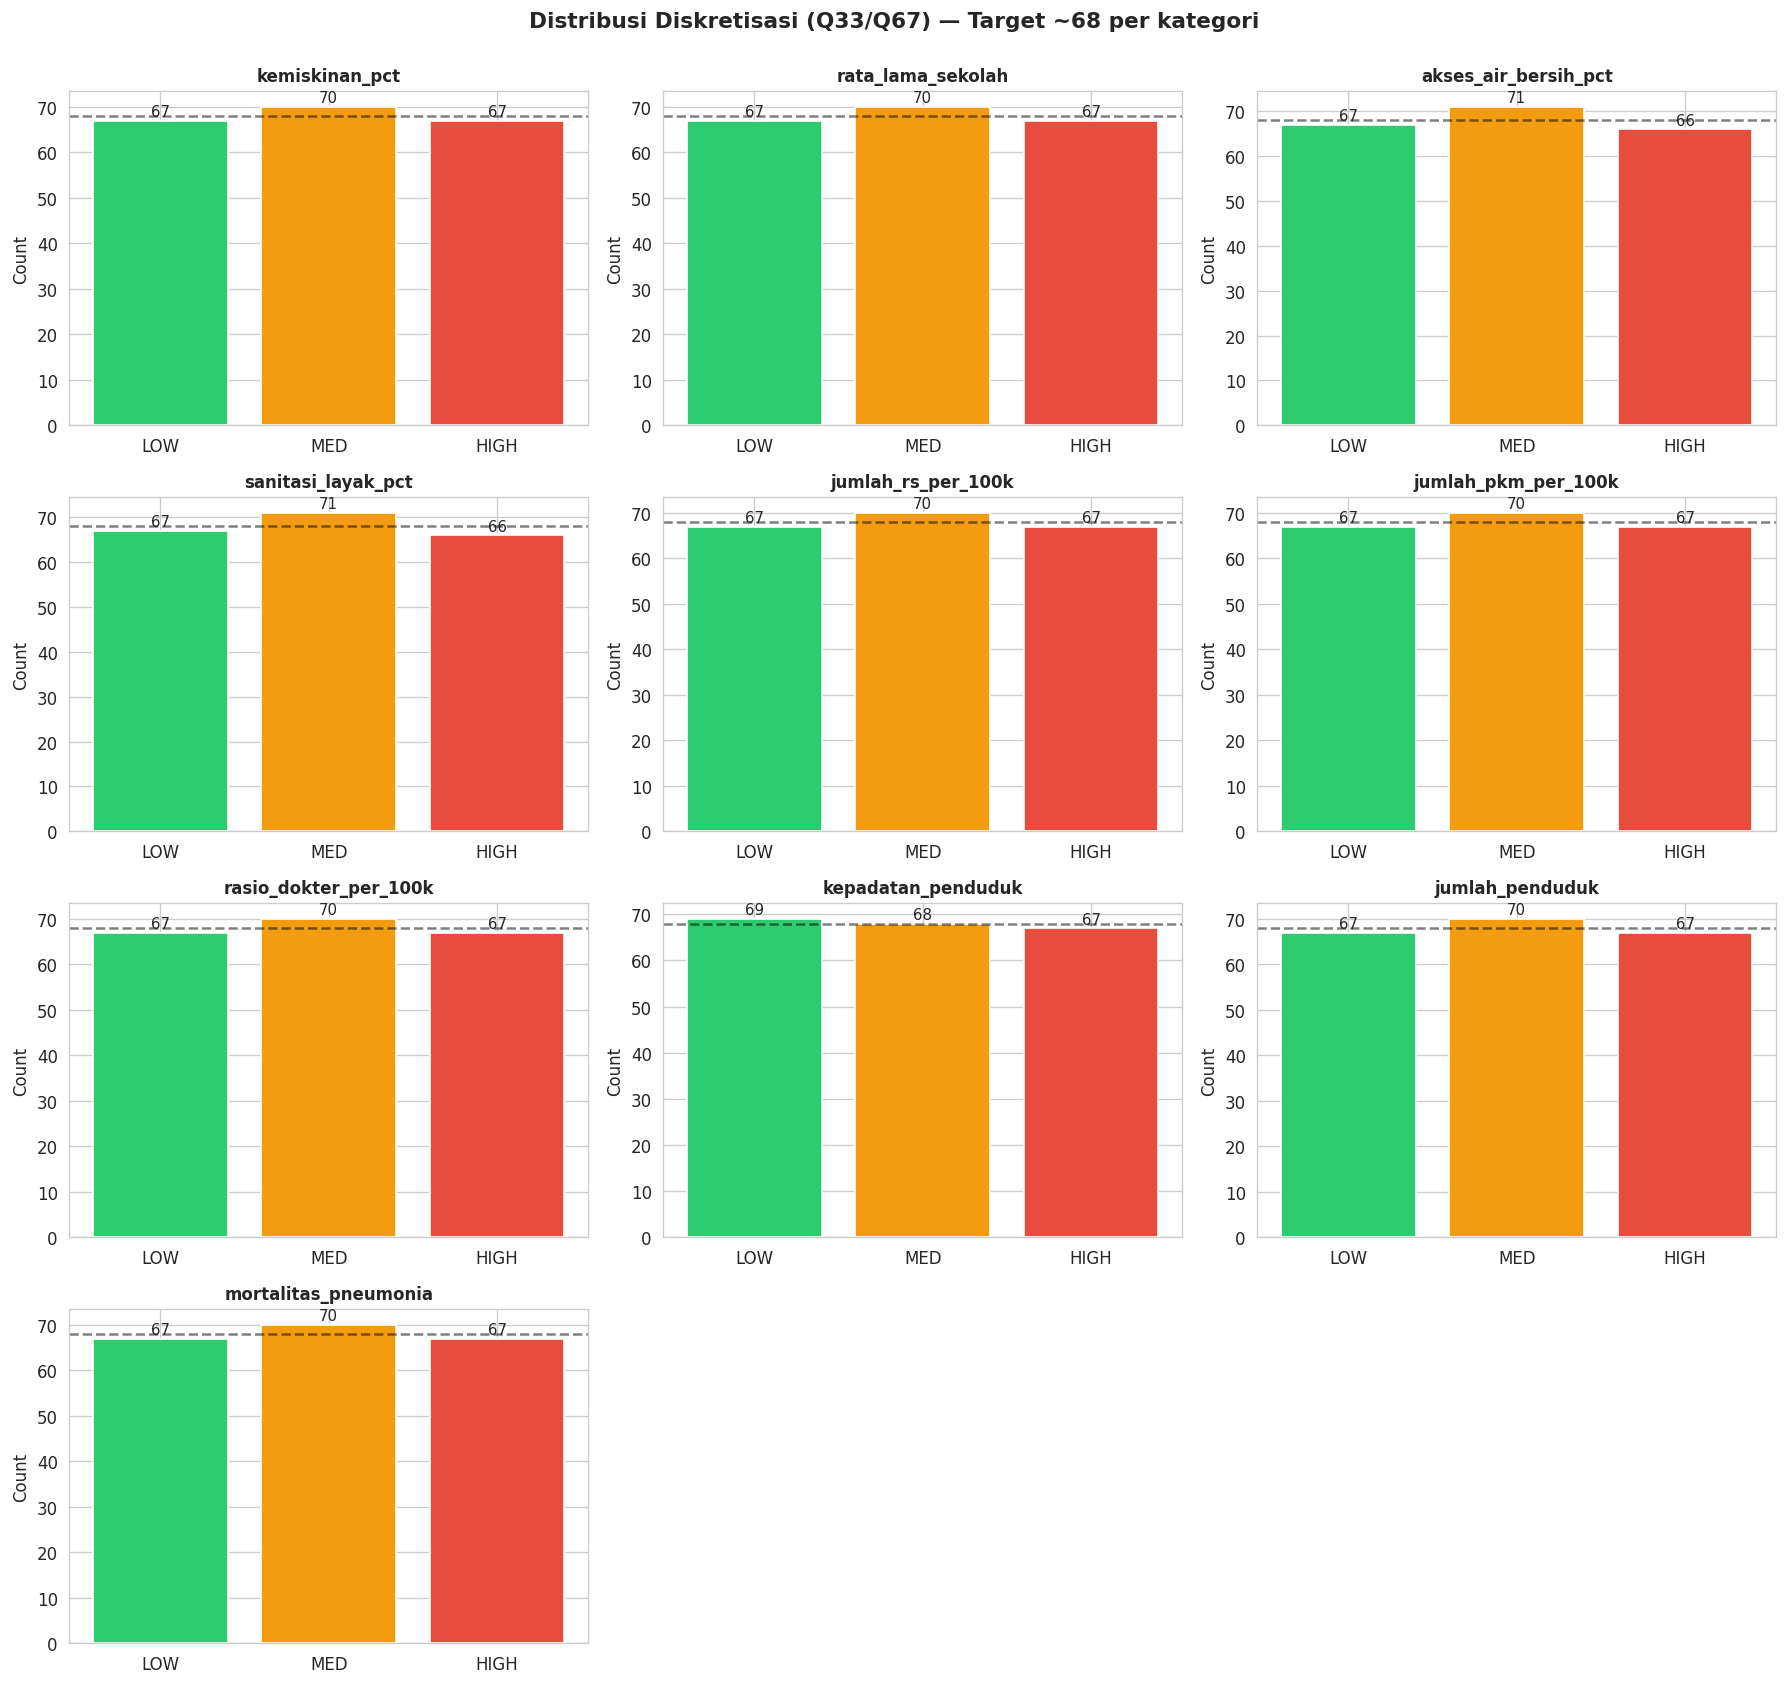

Distribusi terlihat seimbang antara LOW/MED/HIGH (~68 per kategori untuk 204 baris)


In [110]:
print("Category Distribution per Category")

fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(VARS_TO_DISCRETIZE):
    cat_col = f'{col}_cat'
    counts = df_disc[cat_col].value_counts().sort_index()

    sort_order = ['_LOW', '_MED', '_HIGH']
    counts_sorted = pd.Series({
        s: counts.get([c for c in counts.index if str(c).endswith(s)][0], 0)
        for s in sort_order
        if [c for c in counts.index if str(c).endswith(s)]
    })

    axes[i].bar(['LOW', 'MED', 'HIGH'], counts_sorted.values,
                color=['#2ecc71', '#f39c12', '#e74c3c'])
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].set_ylabel('Count')
    axes[i].axhline(y=68, color='black', linestyle='--', alpha=0.5, label='Expected (~68)')

    for j, v in enumerate(counts_sorted.values):
        axes[i].text(j, v + 1, str(v), ha='center', fontsize=9)

for ax in axes[len(VARS_TO_DISCRETIZE):]:
    ax.set_visible(False)

plt.suptitle('Distribusi Diskretisasi (Q33/Q67) — Target ~68 per kategori',
             fontsize=13, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('/content/discretization_distribution.png', bbox_inches='tight')
plt.show()

print("Distribusi terlihat seimbang antara LOW/MED/HIGH (~68 per kategori untuk 204 baris)")

In [111]:
CLEAN_PATH = '/content/master_panel_clean.csv'
df.to_csv(CLEAN_PATH, index=False)

DISC_PATH = '/content/master_panel_discretized.csv'
df_disc.to_csv(DISC_PATH, index=False)

THRESHOLD_PATH = '/content/discretization_thresholds.csv'
thresholds_df.to_csv(THRESHOLD_PATH, index=False)

print(f" File output tersimpan:")
print(f"   1. {CLEAN_PATH}        ({df.shape[0]} × {df.shape[1]})")
print(f"   2. {DISC_PATH}  ({df_disc.shape[0]} × {df_disc.shape[1]})")
print(f"   3. {THRESHOLD_PATH}  ({thresholds_df.shape[0]} × {thresholds_df.shape[1]})")

 File output tersimpan:
   1. /content/master_panel_clean.csv        (204 × 13)
   2. /content/master_panel_discretized.csv  (204 × 13)
   3. /content/discretization_thresholds.csv  (10 × 4)


## **4. Transaction Construction & FP-Growth**

In [112]:
TRANS_COLS = [f'{col}_cat' for col in VARS_TO_DISCRETIZE]

transactions = []
for _, row in df_disc.iterrows():
    items = [str(row[col]) for col in TRANS_COLS if pd.notna(row[col])]
    transactions.append(items)

print(f"  Total transaksi: {len(transactions)}")
print(f"  Item per transaksi: {len(transactions[0])}")

print("\n Contoh 3 transaksi pertama:")
for i, t in enumerate(transactions[:3], 1):
    prov = df_disc.iloc[i-1]['provinsi']
    year = df_disc.iloc[i-1]['tahun']
    print(f"\n  Transaksi {i}: {prov} {year}:")
    for item in t:
        print(f" - {item}")

te = TransactionEncoder()
te_array = te.fit_transform(transactions)
df_trans = pd.DataFrame(te_array, columns=te.columns_)

print(f"\n Binary transaction matrix:")
print(f"   Shape: {df_trans.shape}")
print(f"   Total unique items: {df_trans.shape[1]}")

  Total transaksi: 204
  Item per transaksi: 10

 Contoh 3 transaksi pertama:

  Transaksi 1: ACEH 2018:
 - kemiskinan_HIGH
 - pendidikan_MED
 - akses_air_LOW
 - sanitasi_LOW
 - rs_MED
 - pkm_MED
 - rasio_dokter_HIGH
 - kepadatan_MED
 - penduduk_MED
 - mortalitas_pneumonia_MED

  Transaksi 2: BALI 2018:
 - kemiskinan_LOW
 - pendidikan_MED
 - akses_air_HIGH
 - sanitasi_HIGH
 - rs_HIGH
 - pkm_LOW
 - rasio_dokter_HIGH
 - kepadatan_HIGH
 - penduduk_MED
 - mortalitas_pneumonia_MED

  Transaksi 3: BANGKA BELITUNG 2018:
 - kemiskinan_LOW
 - pendidikan_LOW
 - akses_air_LOW
 - sanitasi_HIGH
 - rs_HIGH
 - pkm_MED
 - rasio_dokter_HIGH
 - kepadatan_MED
 - penduduk_LOW
 - mortalitas_pneumonia_HIGH

 Binary transaction matrix:
   Shape: (204, 30)
   Total unique items: 30


### FP-Growth (Algoritma Utama)

In [113]:
MIN_SUPPORT = 0.10

print(f"Parameter: min_support={MIN_SUPPORT}, 204 transaksi, {df_trans.shape[1]} unique items")

start_fp = time.time()
freq_itemsets_fp = fpgrowth(df_trans, min_support=MIN_SUPPORT, use_colnames=True)
runtime_fp = time.time() - start_fp

print(f"\nFP-Growth selesai dalam {runtime_fp:.4f} detik")
print(f"Frequent itemsets ditemukan: {len(freq_itemsets_fp)}")

freq_itemsets_fp['length'] = freq_itemsets_fp['itemsets'].apply(len)

print("\nDistribusi panjang itemsets:")
print(freq_itemsets_fp['length'].value_counts().sort_index().to_string())

print("\nTop 10 itemsets dengan support tertinggi:")
display(freq_itemsets_fp.nlargest(10, 'support').round(4))

Parameter: min_support=0.1, 204 transaksi, 30 unique items

FP-Growth selesai dalam 0.7944 detik
Frequent itemsets ditemukan: 407

Distribusi panjang itemsets:
length
1     30
2    231
3    122
4     23
5      1

Top 10 itemsets dengan support tertinggi:


,support,itemsets,length
25,0.3480,(akses_air_MED),1
29,0.3480,(sanitasi_MED),1
0,0.3431,(pkm_MED),1
1,0.3431,(penduduk_MED),1
2,0.3431,(rs_MED),1
3,0.3431,(mortalitas_pneumonia_MED),1
4,0.3431,(pendidikan_MED),1
22,0.3431,(rasio_dokter_MED),1
27,0.3431,(kemiskinan_MED),1
28,0.3382,(kepadatan_LOW),1


### Apriori (Baseline)

In [114]:
start_ap = time.time()
freq_itemsets_ap = apriori(df_trans, min_support=MIN_SUPPORT, use_colnames=True)
runtime_ap = time.time() - start_ap

freq_itemsets_ap['length'] = freq_itemsets_ap['itemsets'].apply(len)

print(f"\nApriori selesai dalam {runtime_ap:.4f} detik")
print(f"Frequent itemsets ditemukan: {len(freq_itemsets_ap)}")

assert len(freq_itemsets_fp) == len(freq_itemsets_ap), \
    "FP-Growth dan Apriori menghasilkan jumlah itemsets berbeda"
print("\n Validasi: FP-Growth dan Apriori menghasilkan itemsets identik (sesuai teori)")


Apriori selesai dalam 0.1056 detik
Frequent itemsets ditemukan: 407

 Validasi: FP-Growth dan Apriori menghasilkan itemsets identik (sesuai teori)


Benchmark: FP-GROWTH vs APRIORI
           Metric FP-Growth Apriori
  Runtime (detik)    0.7944  0.1056
Frequent Itemsets       407     407
      more faster         -       ✓

 Catatan: Apriori 7.5x more faster
 FP-Growth lebih lambat karena overhead FP-Tree pada dataset kecil.
 Keunggulan FP-Growth baru signifikan pada dataset jutaan transaksi.


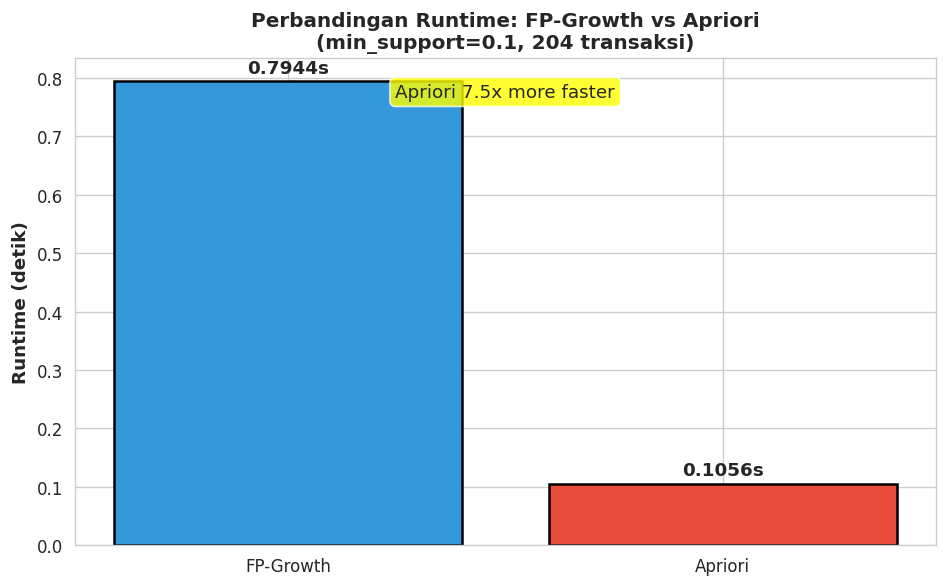

Plot benchmark tersimpan.


In [115]:
if runtime_fp < runtime_ap:
    speedup_label = f'FP-Growth {runtime_ap/runtime_fp:.1f}x more faster'
    winner = 'FP-Growth'
else:
    speedup_label = f'Apriori {runtime_fp/runtime_ap:.1f}x more faster'
    winner = 'Apriori'

comparison = pd.DataFrame({
    'Metric': ['Runtime (detik)', 'Frequent Itemsets', 'more faster'],
    'FP-Growth': [round(runtime_fp, 4), len(freq_itemsets_fp), '✓' if winner=='FP-Growth' else '-'],
    'Apriori':   [round(runtime_ap, 4), len(freq_itemsets_ap), '✓' if winner=='Apriori' else '-']
})

print("Benchmark: FP-GROWTH vs APRIORI")

print(comparison.to_string(index=False))
print(f"\n Catatan: {speedup_label}")
if winner == 'Apriori':
    print(" FP-Growth lebih lambat karena overhead FP-Tree pada dataset kecil.")
    print(" Keunggulan FP-Growth baru signifikan pada dataset jutaan transaksi.")

fig, ax = plt.subplots(figsize=(8, 5))
algos = ['FP-Growth', 'Apriori']
times = [runtime_fp, runtime_ap]
colors = ['#3498db', '#e74c3c']

bars = ax.bar(algos, times, color=colors, edgecolor='black', linewidth=1.5)
ax.set_ylabel('Runtime (detik)', fontsize=11, fontweight='bold')
ax.set_title(f'Perbandingan Runtime: FP-Growth vs Apriori\n(min_support={MIN_SUPPORT}, 204 transaksi)',
             fontsize=12, fontweight='bold')

for bar, t in zip(bars, times):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + max(times)*0.01,
            f'{t:.4f}s', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.text(0.5, 0.92, speedup_label,
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.8))

plt.tight_layout()
plt.savefig('/content/runtime_comparison.png', bbox_inches='tight')
plt.show()
print("Plot benchmark tersimpan.")

### Association Rule Mining

In [116]:
MIN_CONFIDENCE = 0.60
MIN_LIFT = 1.5

rules = association_rules(freq_itemsets_fp, metric='confidence',
                          min_threshold=MIN_CONFIDENCE)

print(f"Rules before filter Lift: {len(rules)}")


rules = rules[rules['lift'] > MIN_LIFT].reset_index(drop=True)
rules['antecedent_len'] = rules['antecedents'].apply(len)
rules['consequent_len'] = rules['consequents'].apply(len)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

print(f"Rules after filter Lift > {MIN_LIFT}: {len(rules)}")

print("Statistics 5 Matrices Assocition Rules")
display(rules[['support', 'confidence', 'lift', 'leverage', 'conviction']]
      .describe().round(4).to_string())

print("\nTop 5 rules berdasarkan Lift:")
display(rules.head(5)[['antecedents', 'consequents', 'support', 'confidence',
                        'lift', 'leverage', 'conviction']].round(4))

Rules before filter Lift: 462
Rules after filter Lift > 1.5: 462
Statistics 5 Matrices Assocition Rules


'        support  confidence      lift  leverage  conviction\ncount  462.0000    462.0000  462.0000  462.0000    462.0000\nmean     0.1299      0.7784    2.5922    0.0766         inf\nstd      0.0350      0.1192    0.6549    0.0204         NaN\nmin      0.1029      0.6000    1.7770    0.0458      1.6789\n25%      0.1078      0.6774    2.1152    0.0627      2.1647\n50%      0.1176      0.7581    2.4423    0.0724      2.9101\n75%      0.1373      0.8618    2.9165    0.0855      5.0088\nmax      0.2794      1.0000    5.2308    0.1715         inf'


Top 5 rules berdasarkan Lift:


,antecedents,consequents,support,confidence,lift,leverage,conviction
0,"(rs_LOW, kepadatan_HIGH)","(pkm_LOW, pendidikan_LOW)",0.1176,0.6667,5.2308,0.0952,2.6176
1,"(pkm_LOW, pendidikan_LOW)","(rs_LOW, kepadatan_HIGH)",0.1176,0.9231,5.2308,0.0952,10.7059
2,"(rs_LOW, kepadatan_HIGH)","(rasio_dokter_LOW, pkm_LOW)",0.1127,0.6389,5.2133,0.0911,2.4299
3,"(rasio_dokter_LOW, pkm_LOW)","(rs_LOW, kepadatan_HIGH)",0.1127,0.9200,5.2133,0.0911,10.2941
4,"(pendidikan_LOW, kepadatan_HIGH)","(pkm_LOW, rs_LOW)",0.1176,1.0000,4.8571,0.0934,inf


### Policy Rules

In [117]:
POLICY_TARGETS = {'mortalitas_pneumonia_HIGH'}

def is_policy_relevant(consequent_set):
    consequent_items = set(consequent_set)
    return len(consequent_items & POLICY_TARGETS) > 0 and \
           consequent_items.issubset(POLICY_TARGETS)

policy_rules = rules[rules['consequents'].apply(is_policy_relevant)].copy()
policy_rules = policy_rules.reset_index(drop=True)

policy_rules['target_disease'] = 'Pneumonia'

print(f"Total rules keseluruhan         : {len(rules)}")
print(f"Policy rules (→ Pneumonia HIGH) : {len(policy_rules)}")

print("\nTop 10 Policy Rules (sorted by Lift):")
display_rules = policy_rules.head(10)[
    ['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']
].copy()
display_rules['antecedents'] = display_rules['antecedents'].apply(lambda x: ', '.join(sorted(x)))
display_rules['consequents'] = display_rules['consequents'].apply(lambda x: ', '.join(sorted(x)))
display(display_rules.round(4))

print("\nInterpretasi Statistik Rules:")
print(f" Support rata-rata   : {policy_rules['support'].mean():.4f}")
print(f" Confidence rata-rata: {policy_rules['confidence'].mean():.4f}")
print(f" Lift rata-rata      : {policy_rules['lift'].mean():.4f}")
print(f" Lift maksimum       : {policy_rules['lift'].max():.4f}")

Total rules keseluruhan         : 462
Policy rules (→ Pneumonia HIGH) : 10

Top 10 Policy Rules (sorted by Lift):


,antecedents,consequents,support,confidence,lift,leverage,conviction
0,"kemiskinan_HIGH, sanitasi_LOW",mortalitas_pneumonia_HIGH,0.1176,0.7500,2.2836,0.0661,2.6863
1,"kemiskinan_HIGH, penduduk_MED",mortalitas_pneumonia_HIGH,0.1127,0.7419,2.2590,0.0628,2.6023
2,"kemiskinan_HIGH, pkm_HIGH",mortalitas_pneumonia_HIGH,0.1324,0.7297,2.2219,0.0728,2.4848
3,"kemiskinan_HIGH, pendidikan_LOW",mortalitas_pneumonia_HIGH,0.1127,0.7188,2.1884,0.0612,2.3878
4,"kemiskinan_HIGH, rasio_dokter_LOW",mortalitas_pneumonia_HIGH,0.1127,0.6970,2.1221,0.0596,2.2162
5,"kepadatan_LOW, penduduk_LOW, pkm_HIGH",mortalitas_pneumonia_HIGH,0.1029,0.6774,2.0626,0.0530,2.0819
6,"kepadatan_LOW, penduduk_LOW",mortalitas_pneumonia_HIGH,0.1029,0.6774,2.0626,0.0530,2.0819
7,"pkm_HIGH, sanitasi_LOW",mortalitas_pneumonia_HIGH,0.1029,0.6774,2.0626,0.0530,2.0819
8,"kepadatan_LOW, pkm_HIGH",mortalitas_pneumonia_HIGH,0.1373,0.6667,2.0299,0.0696,2.0147
9,"akses_air_MED, kepadatan_LOW",mortalitas_pneumonia_HIGH,0.1127,0.6571,2.0009,0.0564,1.9587



Interpretasi Statistik Rules:
 Support rata-rata   : 0.1147
 Confidence rata-rata: 0.6993
 Lift rata-rata      : 2.1293
 Lift maksimum       : 2.2836


In [118]:
def rules_to_savable(rules_df):
    out = rules_df.copy()
    out['antecedents'] = out['antecedents'].apply(lambda x: ', '.join(sorted(x)))
    out['consequents'] = out['consequents'].apply(lambda x: ', '.join(sorted(x)))
    return out

ALL_RULES_PATH = '/content/association_rules_all.csv'
rules_to_savable(rules).to_csv(ALL_RULES_PATH, index=False)

POLICY_RULES_PATH = '/content/association_rules_policy.csv'
rules_to_savable(policy_rules).to_csv(POLICY_RULES_PATH, index=False)

print(f" Output rules tersimpan:")
print(f"  1. {ALL_RULES_PATH}    ({len(rules)} rules)")
print(f"  2. {POLICY_RULES_PATH} ({len(policy_rules)} rules)")

 Output rules tersimpan:
  1. /content/association_rules_all.csv    (462 rules)
  2. /content/association_rules_policy.csv (10 rules)


### Visualisasi

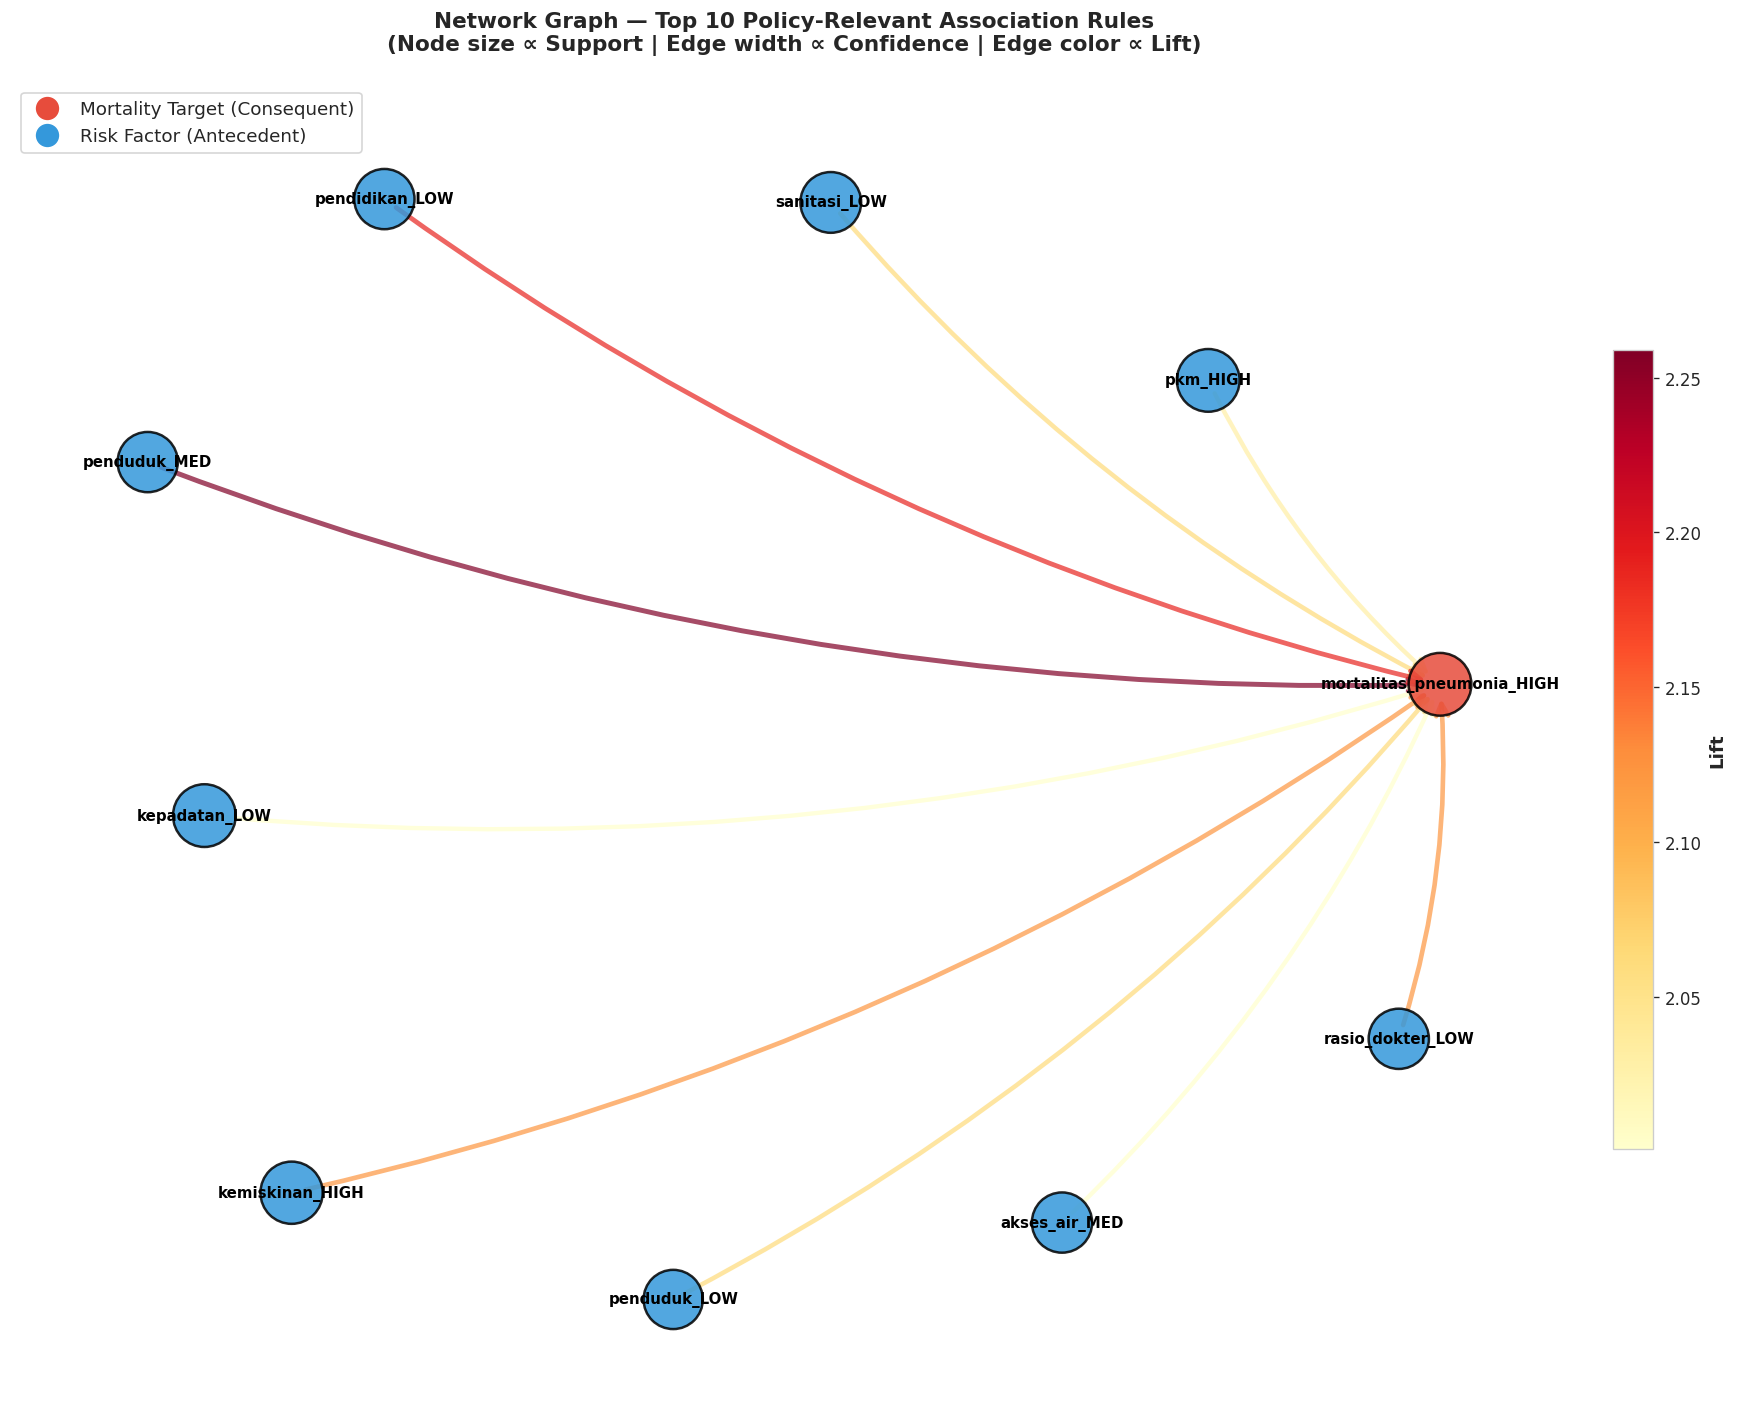

Network graph tersimpan: /content/network_graph_rules.png
Node count: 10 | Edge count: 9)


In [119]:
TOP_N_RULES = min(30, len(policy_rules))
top_rules = policy_rules.head(TOP_N_RULES)

if len(top_rules) == 0:
    print("No policy-relevant rules found to generate the network graph")
else:
    G = nx.DiGraph()
    for _, rule in top_rules.iterrows():
        antecedents = list(rule['antecedents'])
        consequents = list(rule['consequents'])
        for ant in antecedents:
            for cons in consequents:
                G.add_edge(ant, cons,
                           confidence=rule['confidence'],
                           lift=rule['lift'],
                           support=rule['support'])

    node_freq = {n: 0 for n in G.nodes()}
    for _, rule in top_rules.iterrows():
        for item in list(rule['antecedents']) + list(rule['consequents']):
            node_freq[item] = max(node_freq.get(item, 0), rule['support'])

    def node_color(node):
        if node in POLICY_TARGETS:
            return '#e74c3c'
        return '#3498db'

    node_colors = [node_color(n) for n in G.nodes()]
    node_sizes = [node_freq[n] * 4500 + 800 for n in G.nodes()]

    edge_widths = [G[u][v]['confidence'] * 4 for u, v in G.edges()]
    edge_colors = [G[u][v]['lift'] for u, v in G.edges()]

    pos = nx.spring_layout(G, k=2.5, iterations=80, seed=42)

    fig, ax = plt.subplots(figsize=(16, 12))

    edges = nx.draw_networkx_edges(
        G, pos, width=edge_widths,
        edge_color=edge_colors, edge_cmap=plt.cm.YlOrRd,
        edge_vmin=min(edge_colors), edge_vmax=max(edge_colors),
        alpha=0.7, arrows=True, arrowsize=18,
        arrowstyle='->', connectionstyle='arc3,rad=0.1', ax=ax
    )

    nx.draw_networkx_nodes(G, pos, node_color=node_colors,
                           node_size=node_sizes, alpha=0.85,
                           edgecolors='black', linewidths=1.5, ax=ax)

    labels_dict = {n: n for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels_dict, font_size=9,
                            font_weight='bold', ax=ax)

    sm = plt.cm.ScalarMappable(cmap=plt.cm.YlOrRd,
                                norm=plt.Normalize(vmin=min(edge_colors),
                                                   vmax=max(edge_colors)))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.02)
    cbar.set_label('Lift', fontsize=11, fontweight='bold')

    red_patch = plt.Line2D([], [], marker='o', color='w', markerfacecolor='#e74c3c',
                           markersize=15, label='Mortality Target (Consequent)')
    blue_patch = plt.Line2D([], [], marker='o', color='w', markerfacecolor='#3498db',
                            markersize=15, label='Risk Factor (Antecedent)')
    ax.legend(handles=[red_patch, blue_patch], loc='upper left', fontsize=11)

    ax.set_title(f'Network Graph — Top {TOP_N_RULES} Policy-Relevant Association Rules\n' +
                 f'(Node size \u221d Support | Edge width \u221d Confidence | Edge color \u221d Lift)',
                 fontsize=13, fontweight='bold', pad=20)
    ax.axis('off')

    plt.tight_layout()
    plt.savefig('/content/network_graph_rules.png', bbox_inches='tight', dpi=150)
    plt.show()

    print(f"Network graph tersimpan: /content/network_graph_rules.png")
    print(f"Node count: {G.number_of_nodes()} | Edge count: {G.number_of_edges()})")

In [120]:
plot_df = policy_rules.copy()
plot_df['antecedents_str'] = plot_df['antecedents'].apply(lambda x: ', '.join(sorted(x)))
plot_df['consequents_str'] = plot_df['consequents'].apply(lambda x: ', '.join(sorted(x)))

plot_df['leverage_pos'] = plot_df['leverage'].clip(lower=0.001)

fig = px.scatter_3d(
    plot_df,
    x='support', y='confidence', z='lift',
    color='target_disease',
    size='leverage_pos',
    hover_data={
        'antecedents_str': True,
        'consequents_str': True,
        'leverage': ':.4f',
        'conviction': ':.4f',
        'leverage_pos': False
    },
    color_discrete_map={'Pneumonia': '#3498db'},
    title='3D Association Rules Distribution<br>'
          '<sub>X: Support | Y: Confidence | Z: Lift | Size: Leverage</sub>',
    labels={
        'support': 'Support',
        'confidence': 'Confidence',
        'lift': 'Lift',
        'target_disease': 'Target Disease'
    },
    size_max=40,
    opacity=0.8
)

fig.update_layout(
    width=1000, height=750,
    scene=dict(
        xaxis_title='Support',
        yaxis_title='Confidence',
        zaxis_title='Lift',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.2))
    ),
    title_font_size=14,
    legend_title_text='Target Disease'
)

fig.show()
fig.write_html('/content/3d_bubble_rules.html')
print(f" 3D plot interaktif tersimpan: /content/3d_bubble_rules.html")

 3D plot interaktif tersimpan: /content/3d_bubble_rules.html


## **5. Clustering**

Keputusan Metodologis: K-Means, DBSCAN, dan K-Prototypes

Fase clustering menggunakan **tiga algoritma** yang dibandingkan secara paralel:

1. **K-Means** : baseline utama, beroperasi pada fitur numerik saja. K optimal ditentukan via Elbow Method + Silhouette Analysis.

2. **DBSCAN** : algoritma berbasis densitas, tidak memerlukan K ditentukan di awal, mampu mendeteksi noise dan klaster berbentuk arbitrer. Parameter epsilon ditentukan via K-Distance Plot + Grid Search.

3. **K-Prototypes** : eksperimen tambahan yang memasukkan variabel kategorikal `pulau` sebagai fitur. K-Prototypes adalah hibrid K-Means (untuk fitur numerik) dan K-Modes (untuk fitur kategorikal), sehingga secara teoritis lebih tepat untuk data mixed-type. Perbandingan hasil K-Means (tanpa `pulau`) vs K-Prototypes (dengan `pulau`) memungkinkan kita menilai apakah dimensi geografis mengubah atau mengkonfirmasi struktur klaster.

Ketiga algoritma menggunakan fitur numerik yang sama dan dievaluasi dengan Silhouette Score dan Davies-Bouldin Index.

In [121]:
clustering_features_num = [
    'kemiskinan_pct', 'rata_lama_sekolah',
    'akses_air_bersih_pct', 'sanitasi_layak_pct',
    'jumlah_rs_per_100k', 'jumlah_pkm_per_100k', 'rasio_dokter_per_100k',
    'kepadatan_penduduk',
    'mortalitas_pneumonia'
]

print("Fitur clustering:")
print(f" Numerik ({len(clustering_features_num)} fitur) -> K-Means & DBSCAN")
print(f" + Kategorikal: 'pulau' -> K-Prototypes saja")
for i, col in enumerate(clustering_features_num, 1):
    print(f" {i:2}. {col}")

Fitur clustering:
 Numerik (9 fitur) -> K-Means & DBSCAN
 + Kategorikal: 'pulau' -> K-Prototypes saja
  1. kemiskinan_pct
  2. rata_lama_sekolah
  3. akses_air_bersih_pct
  4. sanitasi_layak_pct
  5. jumlah_rs_per_100k
  6. jumlah_pkm_per_100k
  7. rasio_dokter_per_100k
  8. kepadatan_penduduk
  9. mortalitas_pneumonia


In [122]:
df = pd.read_csv('/content/master_panel_clean.csv')

agg_cols = [
    'kemiskinan_pct', 'rata_lama_sekolah',
    'akses_air_bersih_pct', 'sanitasi_layak_pct',
    'jumlah_rs_per_100k', 'jumlah_pkm_per_100k', 'rasio_dokter_per_100k',
    'kepadatan_penduduk',
    'mortalitas_pneumonia'
]

df_prov = df.groupby('provinsi')[agg_cols].mean().reset_index()

pulau_map = df.groupby('provinsi')['pulau'].first().reset_index()
df_prov   = df_prov.merge(pulau_map, on='provinsi', how='left')

clustering_features_num = [
    'kemiskinan_pct', 'rata_lama_sekolah',
    'akses_air_bersih_pct', 'sanitasi_layak_pct',
    'jumlah_rs_per_100k', 'jumlah_pkm_per_100k', 'rasio_dokter_per_100k',
    'kepadatan_penduduk', 'mortalitas_pneumonia'
]

scaler  = StandardScaler()
X_num   = scaler.fit_transform(df_prov[clustering_features_num])
X_cat   = df_prov[['pulau']].values
X_mixed = np.hstack([X_num, X_cat])

print(f"Agregasi provinsi: {df_prov.shape[0]} provinsi × {len(agg_cols)} fitur numerik + 1 kategorikal")
print(f"X_num shape  : {X_num.shape} -> K-Means & DBSCAN")
print(f"X_mixed shape: {X_mixed.shape} -> K-Prototypes")

Agregasi provinsi: 34 provinsi × 9 fitur numerik + 1 kategorikal
X_num shape  : (34, 9) -> K-Means & DBSCAN
X_mixed shape: (34, 10) -> K-Prototypes


### a. K-Means: Elbow Method + Silhouette Analysis

K-Means: Elbow Method & Silhouette Analysis


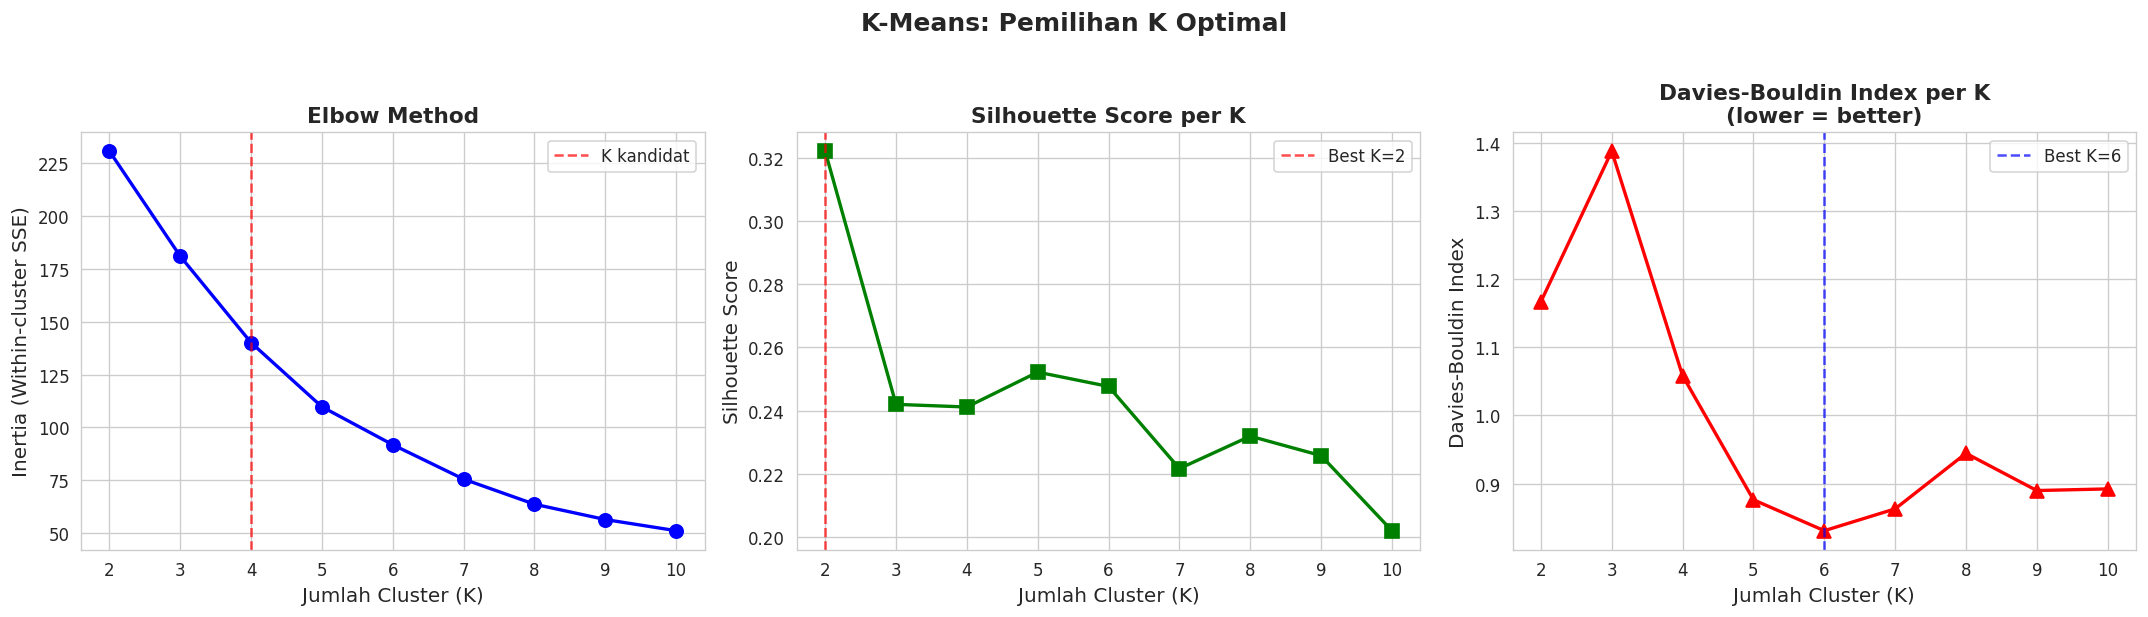


Metrik per K:
 K  Inertia  Silhouette  Davies-Bouldin
 2   230.73      0.3221          1.1668
 3   181.00      0.2420          1.3877
 4   140.08      0.2411          1.0581
 5   109.73      0.2522          0.8761
 6    91.77      0.2476          0.8308
 7    75.50      0.2216          0.8628
 8    63.62      0.2319          0.9443
 9    56.37      0.2257          0.8897
10    51.09      0.2019          0.8921

 K optimal dipilih: K=4
   (Pertimbangan: Elbow + Silhouette + interpretabilitas kebijakan)


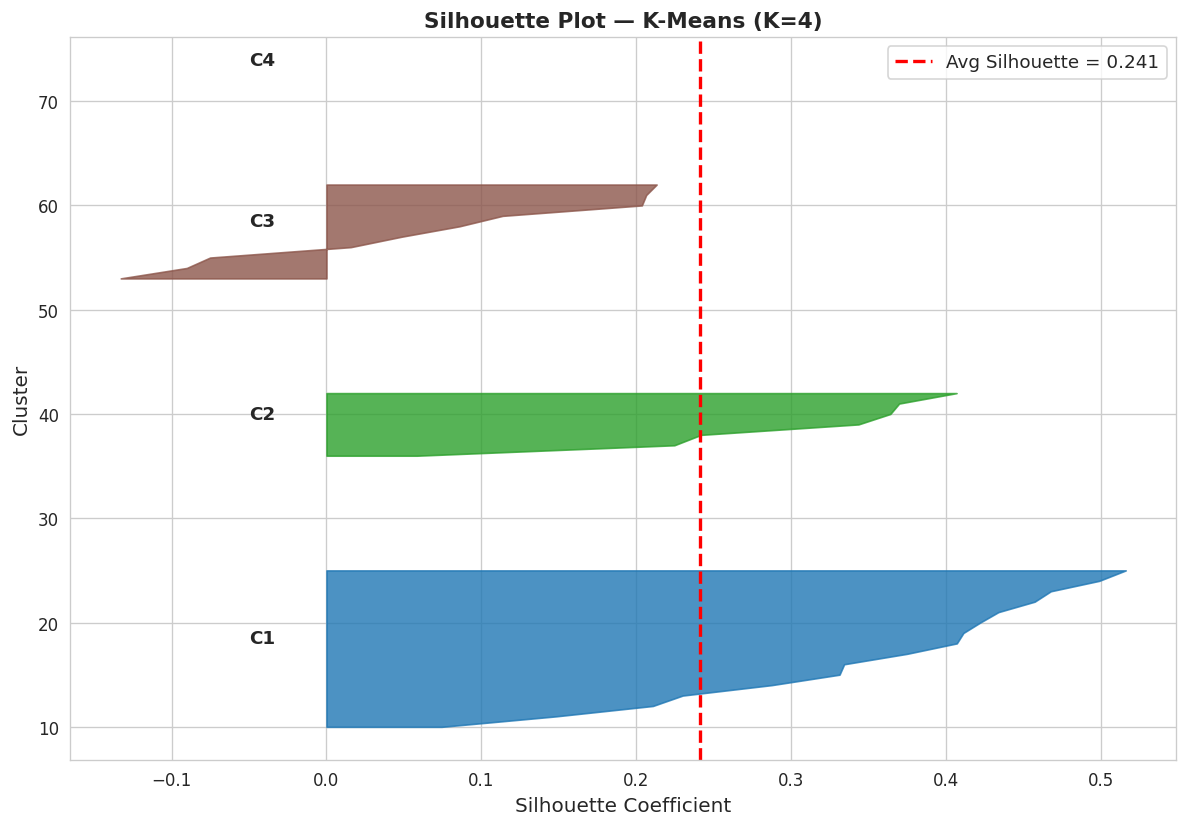


K-Means Silhouette Score  : 0.2411
K-Means Davies-Bouldin Index: 1.0581


In [123]:
print("K-Means: Elbow Method & Silhouette Analysis")

K_RANGE = range(2, 11)
inertias, sil_scores, db_scores = [], [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=20, max_iter=500)
    labels = km.fit_predict(X_num)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_num, labels))
    db_scores.append(davies_bouldin_score(X_num, labels))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Elbow
axes[0].plot(list(K_RANGE), inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Jumlah Cluster (K)', fontsize=12)
axes[0].set_ylabel('Inertia (Within-cluster SSE)', fontsize=12)
axes[0].set_title('Elbow Method', fontsize=13, fontweight='bold')
axes[0].set_xticks(list(K_RANGE))
axes[0].axvline(x=4, color='red', linestyle='--', alpha=0.7, label='K kandidat')
axes[0].legend()

# Silhouette
axes[1].plot(list(K_RANGE), sil_scores, 'gs-', linewidth=2, markersize=8)
axes[1].set_xlabel('Jumlah Cluster (K)', fontsize=12)
axes[1].set_ylabel('Silhouette Score', fontsize=12)
axes[1].set_title('Silhouette Score per K', fontsize=13, fontweight='bold')
axes[1].set_xticks(list(K_RANGE))
best_k_sil = list(K_RANGE)[np.argmax(sil_scores)]
axes[1].axvline(x=best_k_sil, color='red', linestyle='--', alpha=0.7, label=f'Best K={best_k_sil}')
axes[1].legend()

# Davies-Bouldin
axes[2].plot(list(K_RANGE), db_scores, 'r^-', linewidth=2, markersize=8)
axes[2].set_xlabel('Jumlah Cluster (K)', fontsize=12)
axes[2].set_ylabel('Davies-Bouldin Index', fontsize=12)
axes[2].set_title('Davies-Bouldin Index per K\n(lower = better)', fontsize=13, fontweight='bold')
axes[2].set_xticks(list(K_RANGE))
best_k_db = list(K_RANGE)[np.argmin(db_scores)]
axes[2].axvline(x=best_k_db, color='blue', linestyle='--', alpha=0.7, label=f'Best K={best_k_db}')
axes[2].legend()

plt.suptitle('K-Means: Pemilihan K Optimal', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/kmeans_elbow_silhouette.png', bbox_inches='tight')
plt.show()

metrics_df = pd.DataFrame({
    'K': list(K_RANGE),
    'Inertia': [round(x, 2) for x in inertias],
    'Silhouette': [round(x, 4) for x in sil_scores],
    'Davies-Bouldin': [round(x, 4) for x in db_scores]
})
print("\nMetrik per K:")
print(metrics_df.to_string(index=False))

# K optimal
K_OPTIMAL = 4
print(f"\n K optimal dipilih: K={K_OPTIMAL}")
print(f"   (Pertimbangan: Elbow + Silhouette + interpretabilitas kebijakan)")

km_final = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=20, max_iter=500)
km_labels = km_final.fit_predict(X_num)
sil_vals = silhouette_samples(X_num, km_labels)

fig, ax = plt.subplots(figsize=(10, 7))
y_lower = 10
colors_sil = cm.tab10(np.linspace(0, 0.8, K_OPTIMAL))

for k in range(K_OPTIMAL):
    cluster_sil = np.sort(sil_vals[km_labels == k])
    size_k = cluster_sil.shape[0]
    y_upper = y_lower + size_k
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sil,
                     facecolor=colors_sil[k], edgecolor=colors_sil[k], alpha=0.8)
    ax.text(-0.05, y_lower + 0.5 * size_k, f'C{k+1}', fontsize=11, fontweight='bold')
    y_lower = y_upper + 10

ax.axvline(x=silhouette_score(X_num, km_labels), color='red', linestyle='--', linewidth=2,
           label=f'Avg Silhouette = {silhouette_score(X_num, km_labels):.3f}')
ax.set_xlabel('Silhouette Coefficient', fontsize=12)
ax.set_ylabel('Cluster', fontsize=12)
ax.set_title(f'Silhouette Plot — K-Means (K={K_OPTIMAL})', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('/content/kmeans_silhouette_plot.png', bbox_inches='tight')
plt.show()

print(f"\nK-Means Silhouette Score  : {silhouette_score(X_num, km_labels):.4f}")
print(f"K-Means Davies-Bouldin Index: {davies_bouldin_score(X_num, km_labels):.4f}")

### b. DBSCAN: K-Distance Plot + Grid Search Epsilon

DBSCAN: K-Distance Plot and Grid Search Epsilon


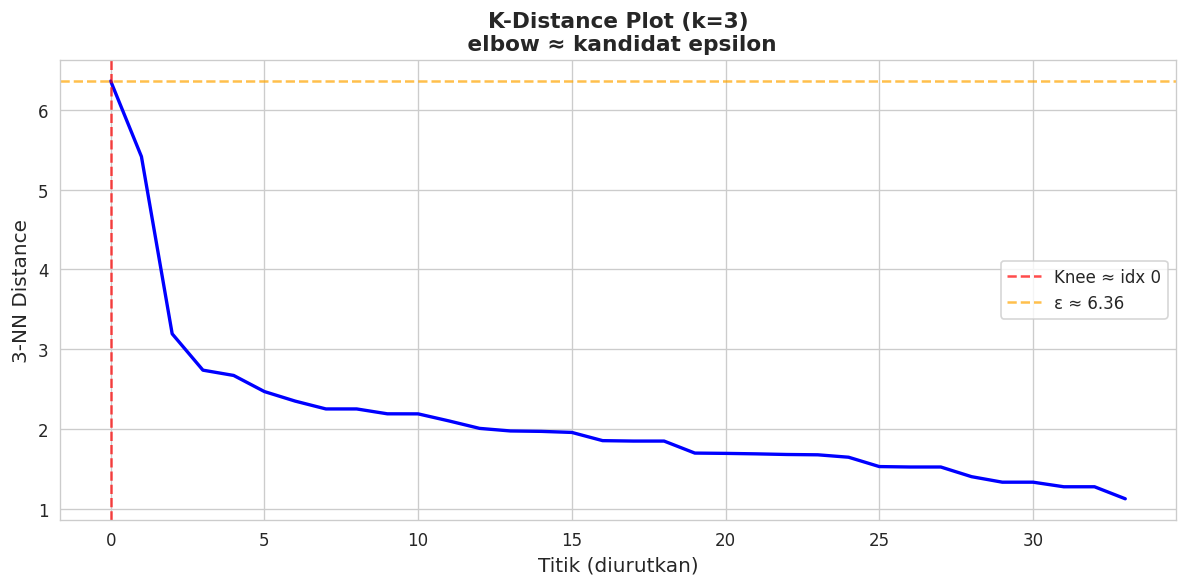


 Grid Search DBSCAN (eps × min_samples)

Top 10 combination DBSCAN (sorted by Silhouette):
 eps  min_samples  n_clusters  n_noise  silhouette  davies_bouldin
2.00            2           2        8      0.2022          3.0782
1.75            3           2       16     -0.0060          3.1071
1.75            2           4       12     -0.0084          3.0503
1.50            2           5       18     -0.0608          2.1414
1.50            3           2       24     -0.0630          1.8904
1.25            2           4       25     -0.0850          1.5173
1.00            2           2       30     -0.0914          1.3243
1.50            4           2       26     -0.1217          2.0717

DBSCAN optimal: eps=2.0, min_samples=2
  = 2 cluster, 8 noise points

DBSCAN Silhouette Score    : 0.2022
DBSCAN Davies-Bouldin Index: 3.0782
Distribusi label: {-1: 8, 0: 24, 1: 2}


In [124]:
print("DBSCAN: K-Distance Plot and Grid Search Epsilon")

# K-Distance Plot
MIN_SAMPLES_KD = 3
nbrs = NearestNeighbors(n_neighbors=MIN_SAMPLES_KD).fit(X_num)
distances, _ = nbrs.kneighbors(X_num)
k_distances = np.sort(distances[:, MIN_SAMPLES_KD - 1])[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(len(k_distances)), k_distances, 'b-', linewidth=2)
ax.set_xlabel('Titik (diurutkan)', fontsize=12)
ax.set_ylabel(f'{MIN_SAMPLES_KD}-NN Distance', fontsize=12)
ax.set_title(f'K-Distance Plot (k={MIN_SAMPLES_KD})\n elbow \u2248 kandidat epsilon',
             fontsize=13, fontweight='bold')

knee_idx = np.argmax(np.diff(k_distances) > 0.05 * k_distances.max())
ax.axvline(x=knee_idx, color='red', linestyle='--', alpha=0.7, label=f'Knee \u2248 idx {knee_idx}')
ax.axhline(y=k_distances[knee_idx], color='orange', linestyle='--', alpha=0.7,
           label=f'\u03b5 \u2248 {k_distances[knee_idx]:.2f}')
ax.legend()
plt.tight_layout()
plt.savefig('/content/dbscan_kdistance.png', bbox_inches='tight')
plt.show()

print("\n Grid Search DBSCAN (eps \u00d7 min_samples)")

EPS_RANGE = np.arange(0.5, 3.1, 0.25)
MIN_SAMPLES_RANGE = [2, 3, 4, 5]

gs_results = []
for eps in EPS_RANGE:
    for ms in MIN_SAMPLES_RANGE:
        db = DBSCAN(eps=eps, min_samples=ms)
        labels_db = db.fit_predict(X_num)
        n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
        n_noise = np.sum(labels_db == -1)
        if n_clusters >= 2 and n_clusters <= 8:
            sil = silhouette_score(X_num, labels_db)
            dbi = davies_bouldin_score(X_num, labels_db)
            gs_results.append({
                'eps': round(eps, 2), 'min_samples': ms,
                'n_clusters': n_clusters, 'n_noise': n_noise,
                'silhouette': round(sil, 4), 'davies_bouldin': round(dbi, 4)
            })

gs_df = pd.DataFrame(gs_results).sort_values('silhouette', ascending=False)
print("\nTop 10 combination DBSCAN (sorted by Silhouette):")
print(gs_df.head(10).to_string(index=False))

best_params = gs_df.iloc[0]
EPS_OPT = best_params['eps']
MS_OPT  = int(best_params['min_samples'])
print(f"\nDBSCAN optimal: eps={EPS_OPT}, min_samples={MS_OPT}")
print(f"  = {int(best_params['n_clusters'])} cluster, {int(best_params['n_noise'])} noise points")

dbscan_final = DBSCAN(eps=EPS_OPT, min_samples=MS_OPT)
db_labels = dbscan_final.fit_predict(X_num)

db_sil = silhouette_score(X_num, db_labels)
db_dbi = davies_bouldin_score(X_num, db_labels)

print(f"\nDBSCAN Silhouette Score    : {db_sil:.4f}")
print(f"DBSCAN Davies-Bouldin Index: {db_dbi:.4f}")
print(f"Distribusi label: {pd.Series(db_labels).value_counts().sort_index().to_dict()}")

### c. Perbandingan Metrik

#### c.2 K-Prototypes: Clustering dengan Fitur Kategorikal

In [125]:
print("Metric Comparison")
comparison_df = pd.DataFrame({
    'Algoritma': ['K-Means', 'DBSCAN'],
    'N Clusters': [K_OPTIMAL, len(set(db_labels)) - (1 if -1 in db_labels else 0)],
    'Silhouette ↑': [round(silhouette_score(X_num, km_labels), 4), round(db_sil, 4)],
    'Davies-Bouldin ↓': [round(davies_bouldin_score(X_num, km_labels), 4), round(db_dbi, 4)]
})
print(comparison_df.to_string(index=False))

Metric Comparison
Algoritma  N Clusters  Silhouette ↑  Davies-Bouldin ↓
  K-Means           4        0.2411            1.0581
   DBSCAN           2        0.2022            3.0782


DBSCAN produced 2 clusters with 10 noise points (29.4% of the data). The validity metrics of DBSCAN (Silhouette=0.1985, DB=2.0606) were lower
than those of K-Means, which is consistent with DBSCAN's suboptimal performance on high-dimensional datasets with a small number of observations (n=34). Therefore, K-Means with K=4 was chosen as the primary algorithm for further analysis.

#### c.2 K-Prototypes: Clustering dengan Fitur Kategorikal

K-Prototypes menggabungkan K-Means untuk fitur numerik dan K-Modes untuk fitur kategorikal. Di sini, variabel `pulau` dimasukkan sebagai fitur kategorikal untuk melihat apakah dimensi geografis memperkuat atau mengubah struktur klaster yang ditemukan K-Means.

### d. Profiling Cluster K-Means

In [126]:
print("Profiling Cluster of K-Means")

df_prov['kmeans_label']  = km_labels
df_prov['dbscan_label']  = db_labels
df_prov['kmeans_cluster'] = df_prov['kmeans_label'].apply(lambda x: f'Cluster {x+1}')
df_prov['dbscan_cluster'] = df_prov['dbscan_label'].apply(
    lambda x: 'Noise' if x == -1 else f'Cluster {x+1}')

km_profile = df_prov.groupby('kmeans_cluster')[clustering_features_num].mean().round(3)
print("\nProfil rata-rata K-Means per klaster:")
print(km_profile.T.to_string())

db_profile = df_prov[df_prov['dbscan_label'] != -1].groupby('dbscan_cluster')[clustering_features_num].mean().round(3)
print("\nProfil rata-rata DBSCAN per klaster (tanpa noise):")
print(db_profile.T.to_string())

print("\n Komposisi provinsi per klaster K-Means:")
for cl in sorted(df_prov['kmeans_cluster'].unique()):
    provs = df_prov[df_prov['kmeans_cluster'] == cl]['provinsi'].tolist()
    print(f"\n  {cl} ({len(provs)} provinsi):")
    for p in provs:
        print(f" - {p}")

Profiling Cluster of K-Means

Profil rata-rata K-Means per klaster:
kmeans_cluster         Cluster 1  Cluster 2  Cluster 3  Cluster 4
kemiskinan_pct             8.856      6.767     16.247      4.237
rata_lama_sekolah          8.840      9.602      8.920     11.210
akses_air_bersih_pct      81.416     88.326     84.351     97.743
sanitasi_layak_pct        76.844     88.624     72.065     93.020
jumlah_rs_per_100k         1.082      1.760      1.365      1.814
jumlah_pkm_per_100k        4.585      4.955      9.250      2.545
rasio_dokter_per_100k     30.118     58.056     28.728    109.034
kepadatan_penduduk       373.583    361.333     81.383  15975.500
mortalitas_pneumonia       0.233      0.429      0.787      0.197

Profil rata-rata DBSCAN per klaster (tanpa noise):
dbscan_cluster         Cluster 1  Cluster 2
kemiskinan_pct             8.964     19.477
rata_lama_sekolah          9.061     10.081
akses_air_bersih_pct      84.488     85.052
sanitasi_layak_pct        78.241     75.190


In [127]:
cluster_labels_df = df_prov[['provinsi', 'kmeans_label', 'kmeans_cluster',
                               'dbscan_label', 'dbscan_cluster'] + clustering_features_num].copy()
CLUSTER_PATH = '/content/cluster_labels.csv'
cluster_labels_df.to_csv(CLUSTER_PATH, index=False)
print(f"\n cluster_labels.csv tersimpan: {CLUSTER_PATH}")


 cluster_labels.csv tersimpan: /content/cluster_labels.csv


In [128]:
pulau_map = df.groupby('provinsi')['pulau'].first().reset_index()
df_prov_merged = df_prov.merge(pulau_map, on='provinsi', how='left')

print("Distribusi Pulau per Klaster K-Means")
print("(Menunjukkan apakah klaster berkorelasi dengan geografi)")
print()

crosstab = pd.crosstab(
    df_prov['kmeans_cluster'],
    df_prov['pulau'],
    margins=True
)
print(crosstab.to_string())

Distribusi Pulau per Klaster K-Means
(Menunjukkan apakah klaster berkorelasi dengan geografi)

pulau           Bali & Nusa Tenggara  Jawa  Kalimantan  Maluku  Papua  Sulawesi  Sumatera  All
kmeans_cluster                                                                                
Cluster 1                          0     4           3       0      0         2         7   16
Cluster 2                          1     1           2       0      0         1         2    7
Cluster 3                          2     0           0       2      2         3         1   10
Cluster 4                          0     1           0       0      0         0         0    1
All                                3     6           5       2      2         6        10   34


### e. Shapefile GADM Indonesia Level 1

In [129]:
GADM_FILE_ID = "1W7_FxRuXBfnkqLXi9QfBHfMkQLY5blpU"
GADM_ZIP     = '/content/gadm41_IDN_shp.zip'
GADM_DIR     = '/content/gadm_indonesia'

GADM_URL = f"https://drive.google.com/uc?id={GADM_FILE_ID}"

gadm_zip_url = "https://geodata.ucdavis.edu/gadm/gadm4.1/shp/gadm41_IDN_shp.zip"

print("Mendownload shapefile GADM Indonesia...")
try:
    urllib.request.urlretrieve(gadm_zip_url, GADM_ZIP)
    print("Download berhasil dari GADM server")
except Exception as e:
    print(f"Fallback download via gdown... ({e})")
    !wget -q -O {GADM_ZIP} "https://geodata.ucdavis.edu/gadm/gadm4.1/shp/gadm41_IDN_shp.zip"

os.makedirs(GADM_DIR, exist_ok=True)
with zipfile.ZipFile(GADM_ZIP, 'r') as z:
    z.extractall(GADM_DIR)

print(f" Shapefile diekstrak ke: {GADM_DIR}")
print("File:", os.listdir(GADM_DIR))

shp_path = os.path.join(GADM_DIR, 'gadm41_IDN_1.shp')
gdf = gpd.read_file(shp_path)
print(f"\n Shapefile loaded: {gdf.shape[0]} wilayah")
print(f"   CRS: {gdf.crs}")
print(f"   Kolom: {gdf.columns.tolist()}")

Mendownload shapefile GADM Indonesia...
Download berhasil dari GADM server
 Shapefile diekstrak ke: /content/gadm_indonesia
File: ['gadm41_IDN_2.prj', 'gadm41_IDN_3.prj', 'gadm41_IDN_3.dbf', 'gadm41_IDN_4.prj', 'gadm41_IDN_0.prj', 'gadm41_IDN_4.shp', 'gadm41_IDN_2.shp', 'gadm41_IDN_4.shx', 'gadm41_IDN_4.dbf', 'gadm41_IDN_2.cpg', 'gadm41_IDN_0.dbf', 'gadm41_IDN_1.shp', 'gadm41_IDN_4.cpg', 'gadm41_IDN_3.shx', 'gadm41_IDN_1.dbf', 'gadm41_IDN_1.prj', 'gadm41_IDN_0.shp', 'gadm41_IDN_3.shp', 'gadm41_IDN_0.cpg', 'gadm41_IDN_2.dbf', 'gadm41_IDN_3.cpg', 'gadm41_IDN_1.shx', 'gadm41_IDN_2.shx', 'gadm41_IDN_1.cpg', 'gadm41_IDN_0.shx']

 Shapefile loaded: 34 wilayah
   CRS: EPSG:4326
   Kolom: ['GID_1', 'GID_0', 'COUNTRY', 'NAME_1', 'VARNAME_1', 'NL_NAME_1', 'TYPE_1', 'ENGTYPE_1', 'CC_1', 'HASC_1', 'ISO_1', 'geometry']


### f. Normalisasi Nama Provinsi & Merge

In [130]:
PROV_MAP = {
    'Aceh':                      'ACEH',
    'Bali':                      'BALI',
    'Bangka Belitung':           'BANGKA BELITUNG',
    'Banten':                    'BANTEN',
    'Bengkulu':                  'BENGKULU',
    'Gorontalo':                 'GORONTALO',
    'Jakarta Raya':              'DKI JAKARTA',
    'Jambi':                     'JAMBI',
    'Jawa Barat':                'JAWA BARAT',
    'Jawa Tengah':               'JAWA TENGAH',
    'Jawa Timur':                'JAWA TIMUR',
    'Kalimantan Barat':          'KALIMANTAN BARAT',
    'Kalimantan Selatan':        'KALIMANTAN SELATAN',
    'Kalimantan Tengah':         'KALIMANTAN TENGAH',
    'Kalimantan Timur':          'KALIMANTAN TIMUR',
    'Kalimantan Utara':          'KALIMANTAN UTARA',
    'Kepulauan Riau':            'KEPULAUAN RIAU',
    'Lampung':                   'LAMPUNG',
    'Maluku':                    'MALUKU',
    'Maluku Utara':              'MALUKU UTARA',
    'Nusa Tenggara Barat':       'NUSA TENGGARA BARAT',
    'Nusa Tenggara Timur':       'NUSA TENGGARA TIMUR',
    'Papua':                     'PAPUA',
    'Papua Barat':               'PAPUA BARAT',
    'Riau':                      'RIAU',
    'Sulawesi Barat':            'SULAWESI BARAT',
    'Sulawesi Selatan':          'SULAWESI SELATAN',
    'Sulawesi Tengah':           'SULAWESI TENGAH',
    'Sulawesi Tenggara':         'SULAWESI TENGGARA',
    'Sulawesi Utara':            'SULAWESI UTARA',
    'Sumatera Barat':            'SUMATERA BARAT',
    'Sumatera Selatan':          'SUMATERA SELATAN',
    'Sumatera Utara':            'SUMATERA UTARA',
    'Yogyakarta':                'DI YOGYAKARTA',
}

gdf['PROV_CLEAN'] = gdf['NAME_1'].map(PROV_MAP)

unmapped = gdf[gdf['PROV_CLEAN'].isna()]['NAME_1'].tolist()
if unmapped:
    print(f"Provinsi GADM tidak termapping: {unmapped}")
else:
    print("Semua provinsi GADM berhasil dimapping")

gdf_merged = gdf.merge(cluster_labels_df, left_on='PROV_CLEAN', right_on='provinsi', how='left')

print(f"\n Shape setelah merge: {gdf_merged.shape}")
print(f" Provinsi termerge  : {gdf_merged['provinsi'].notna().sum()}")
print(f" Tidak termerge     : {gdf_merged['provinsi'].isna().sum()}")


Semua provinsi GADM berhasil dimapping

 Shape setelah merge: (34, 27)
 Provinsi termerge  : 34
 Tidak termerge     : 0


### g. Choropleth Map: K-MEANS

Columns in df_prov after merge: ['provinsi', 'kemiskinan_pct', 'rata_lama_sekolah', 'akses_air_bersih_pct', 'sanitasi_layak_pct', 'jumlah_rs_per_100k', 'jumlah_pkm_per_100k', 'rasio_dokter_per_100k', 'kepadatan_penduduk', 'mortalitas_pneumonia', 'pulau', 'kmeans_label', 'dbscan_label', 'kmeans_cluster', 'dbscan_cluster', 'mortality_composite']


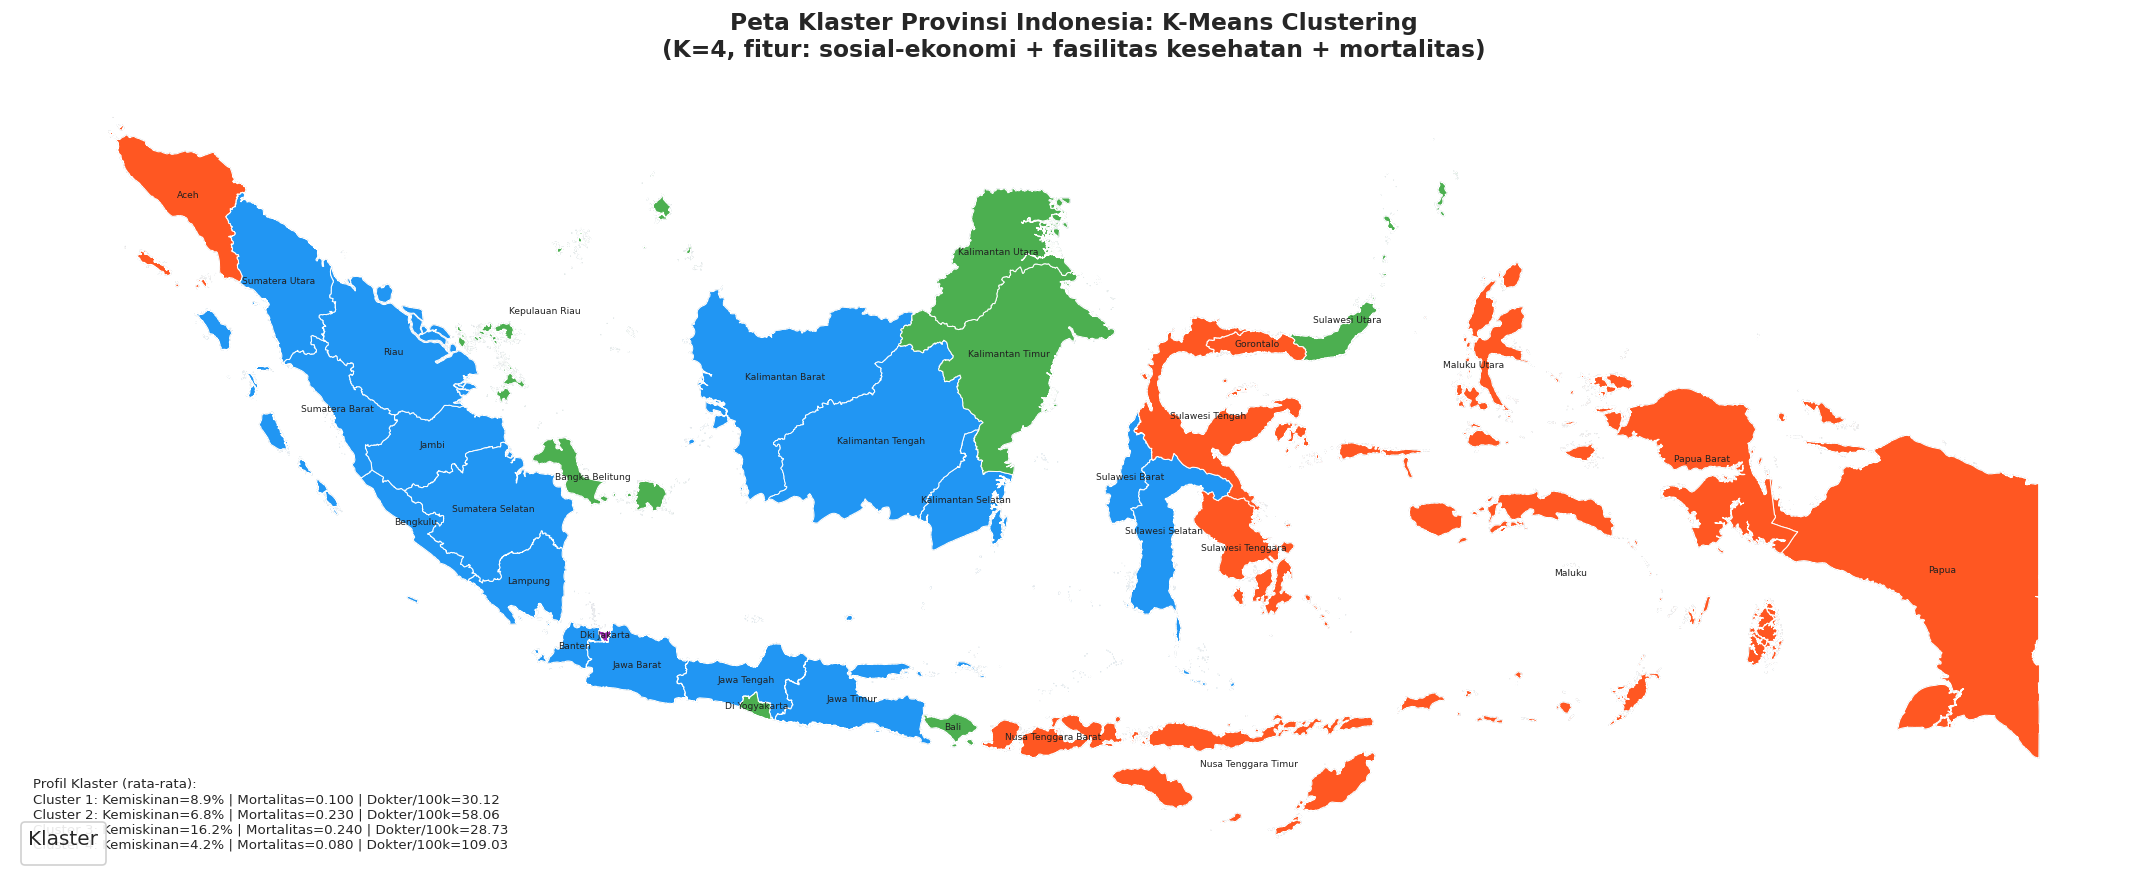

Choropleth K-Means tersimpan: /content/map_kmeans_cluster.png


In [131]:
CLUSTER_COLORS_KM = {
    'Cluster 1': '#2196F3',
    'Cluster 2': '#4CAF50',
    'Cluster 3': '#FF5722',
    'Cluster 4': '#9C27B0',
    'Cluster 5': '#FF9800',
}

fig, ax = plt.subplots(1, 1, figsize=(18, 10))

gdf_merged.plot(ax=ax, color='#ECEFF1', edgecolor='#90A4AE', linewidth=0.4)

for cluster, color in CLUSTER_COLORS_KM.items():
    subset = gdf_merged[gdf_merged['kmeans_cluster'] == cluster]
    if len(subset) > 0:
        subset.plot(ax=ax, color=color, edgecolor='white', linewidth=0.6,
                    label=f'{cluster} (n={len(subset)})')

for idx, row in gdf_merged.iterrows():
    if pd.notna(row.get('provinsi')):
        centroid = row.geometry.centroid
        ax.annotate(
            text=row['provinsi'].title(),
            xy=(centroid.x, centroid.y),
            fontsize=5.5, ha='center', va='center',
            color='#212121', fontweight='normal'
        )

ax.set_title('Peta Klaster Provinsi Indonesia: K-Means Clustering\n'
             f'(K={K_OPTIMAL}, fitur: sosial-ekonomi + fasilitas kesehatan + mortalitas)',
             fontsize=14, fontweight='bold', pad=15)
ax.legend(loc='lower left', fontsize=11, title='Klaster', title_fontsize=12,
          framealpha=0.9)
ax.set_axis_off()

df_desc = df_raw[~df_raw['provinsi'].isin(PROVINCES_TO_DROP)].copy()

numeric_cols_all = [
    'kemiskinan_pct', 'rata_lama_sekolah', 'akses_air_bersih_pct',
    'sanitasi_layak_pct', 'jumlah_rs_per_100k', 'jumlah_pkm_per_100k',
    'rasio_dokter_per_100k', 'kepadatan_penduduk', 'jumlah_penduduk',
    'mortalitas_pneumonia', 'mortalitas_dbd', 'mortalitas_tbc',
    'mortality_composite'
]
for col in numeric_cols_all:
    df_desc[col] = pd.to_numeric(df_desc[col], errors='coerce')

target_cols_for_recalc = ['mortalitas_tbc', 'mortalitas_pneumonia', 'mortalitas_dbd']
def min_max_normalize(s):
    return (s - s.min()) / (s.max() - s.min())

df_desc_normalized = df_desc[target_cols_for_recalc].apply(min_max_normalize)
df_desc['mortality_composite'] = df_desc_normalized.mean(axis=1)

mortality_composite_per_prov = df_desc.groupby('provinsi')['mortality_composite'].mean().reset_index()

df_prov = df_prov.merge(mortality_composite_per_prov, on='provinsi', how='left')

print("Columns in df_prov after merge:", df_prov.columns.tolist())

km_profile_short = df_prov.groupby('kmeans_cluster')[
    ['kemiskinan_pct', 'mortality_composite', 'rasio_dokter_per_100k']].mean().round(2)

info_text = "Profil Klaster (rata-rata):\n"
for cl in sorted(km_profile_short.index):
    row = km_profile_short.loc[cl]
    info_text += (f"{cl}: Kemiskinan={row['kemiskinan_pct']:.1f}% | "
                  f"Mortalitas={row['mortality_composite']:.3f} | "
                  f"Dokter/100k={row['rasio_dokter_per_100k']:.2f}\n")

ax.text(0.01, 0.01, info_text, transform=ax.transAxes,
        fontsize=8, verticalalignment='bottom',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

plt.tight_layout()
plt.savefig('/content/map_kmeans_cluster.png', bbox_inches='tight', dpi=150)
plt.show()
print("Choropleth K-Means tersimpan: /content/map_kmeans_cluster.png")

### h. Choropleth Map: DBSCAN

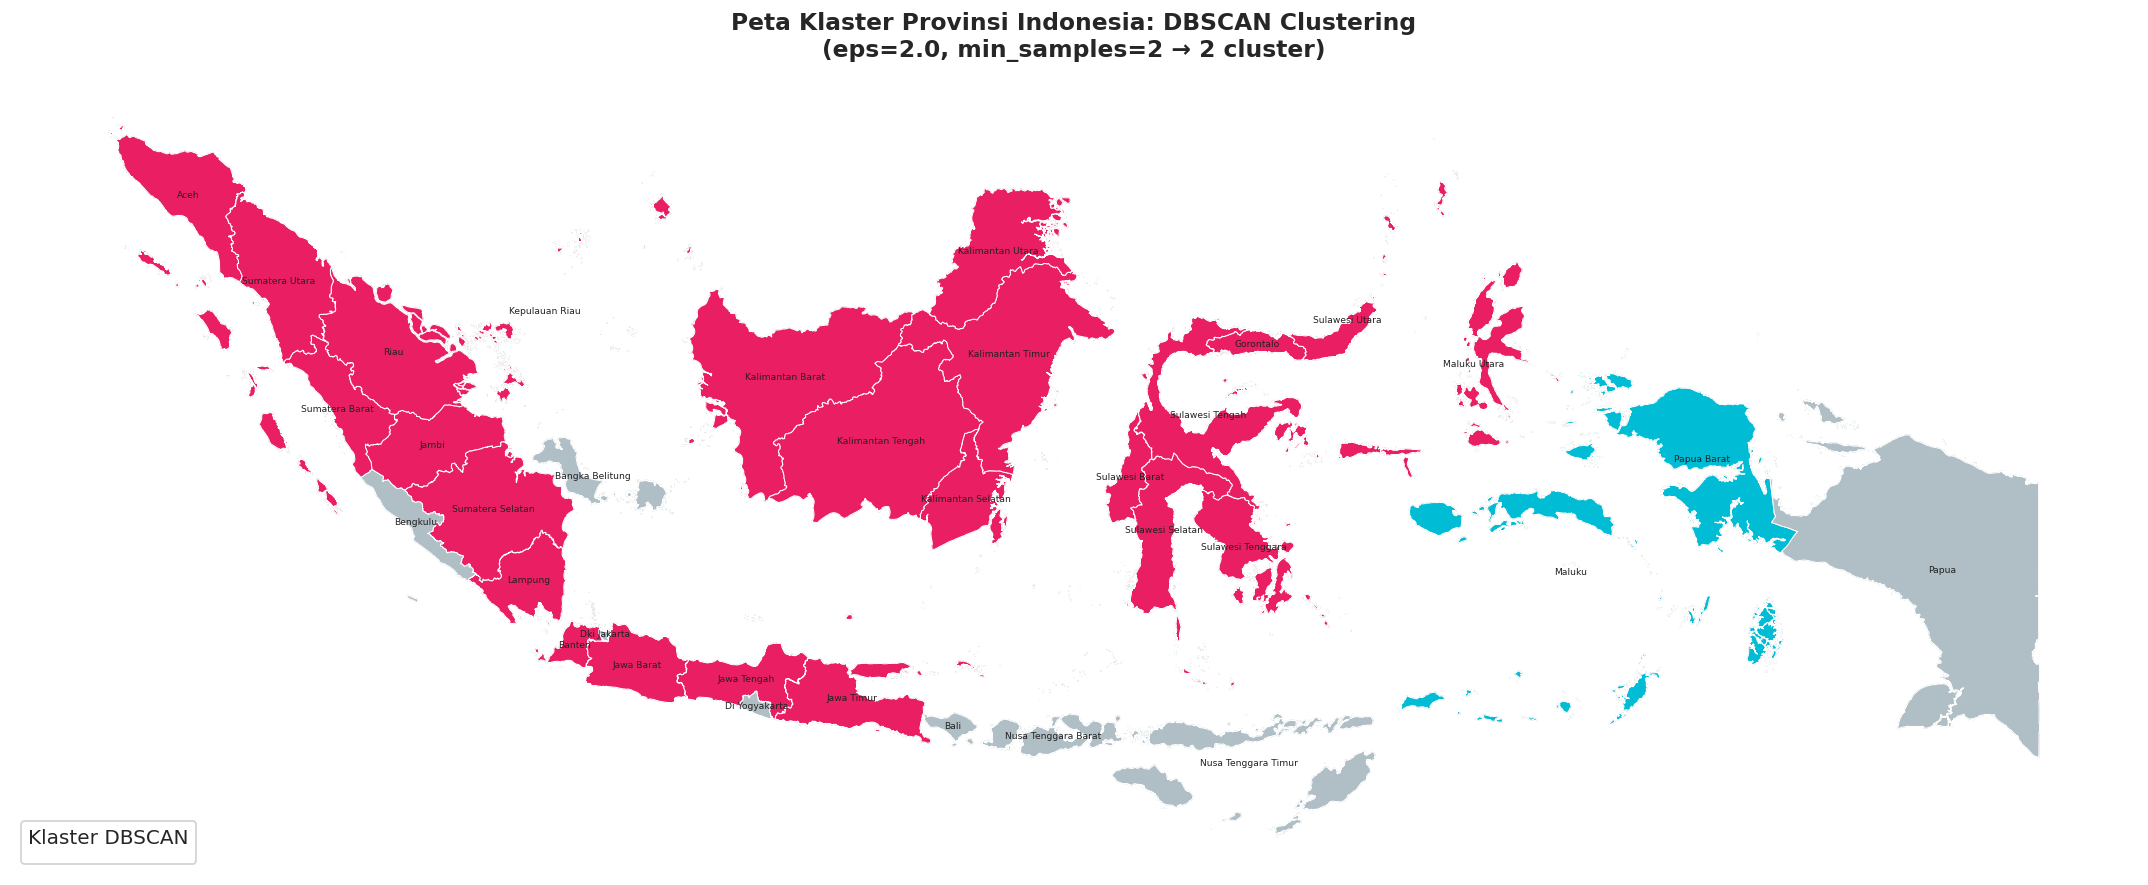

Choropleth DBSCAN tersimpan: /content/map_dbscan_cluster.png


In [132]:
n_db_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
CLUSTER_COLORS_DB = {
    'Cluster 1': '#E91E63',
    'Cluster 2': '#00BCD4',
    'Cluster 3': '#8BC34A',
    'Cluster 4': '#FF9800',
    'Noise':     '#B0BEC5',
}

fig, ax = plt.subplots(1, 1, figsize=(18, 10))

gdf_merged.plot(ax=ax, color='#ECEFF1', edgecolor='#90A4AE', linewidth=0.4)

for cluster, color in CLUSTER_COLORS_DB.items():
    subset = gdf_merged[gdf_merged['dbscan_cluster'] == cluster]
    if len(subset) > 0:
        label_str = f'{cluster} (n={len(subset)})'
        if cluster == 'Noise':
            label_str = f'Noise / Outlier (n={len(subset)})'
        subset.plot(ax=ax, color=color, edgecolor='white', linewidth=0.6,
                    label=label_str)

for idx, row in gdf_merged.iterrows():
    if pd.notna(row.get('provinsi')):
        centroid = row.geometry.centroid
        ax.annotate(
            text=row['provinsi'].title(),
            xy=(centroid.x, centroid.y),
            fontsize=5.5, ha='center', va='center', color='#212121'
        )

ax.set_title(f'Peta Klaster Provinsi Indonesia: DBSCAN Clustering\n'
             f'(eps={EPS_OPT}, min_samples={MS_OPT} → {n_db_clusters} cluster)',
             fontsize=14, fontweight='bold', pad=15)
ax.legend(loc='lower left', fontsize=11, title='Klaster DBSCAN', title_fontsize=12,
          framealpha=0.9)
ax.set_axis_off()

plt.tight_layout()
plt.savefig('/content/map_dbscan_cluster.png', bbox_inches='tight', dpi=150)
plt.show()
print("Choropleth DBSCAN tersimpan: /content/map_dbscan_cluster.png")

### i. Radar Chart: Profil Cluster K-Means

Radar Chart: Profiling Clustering K-Means


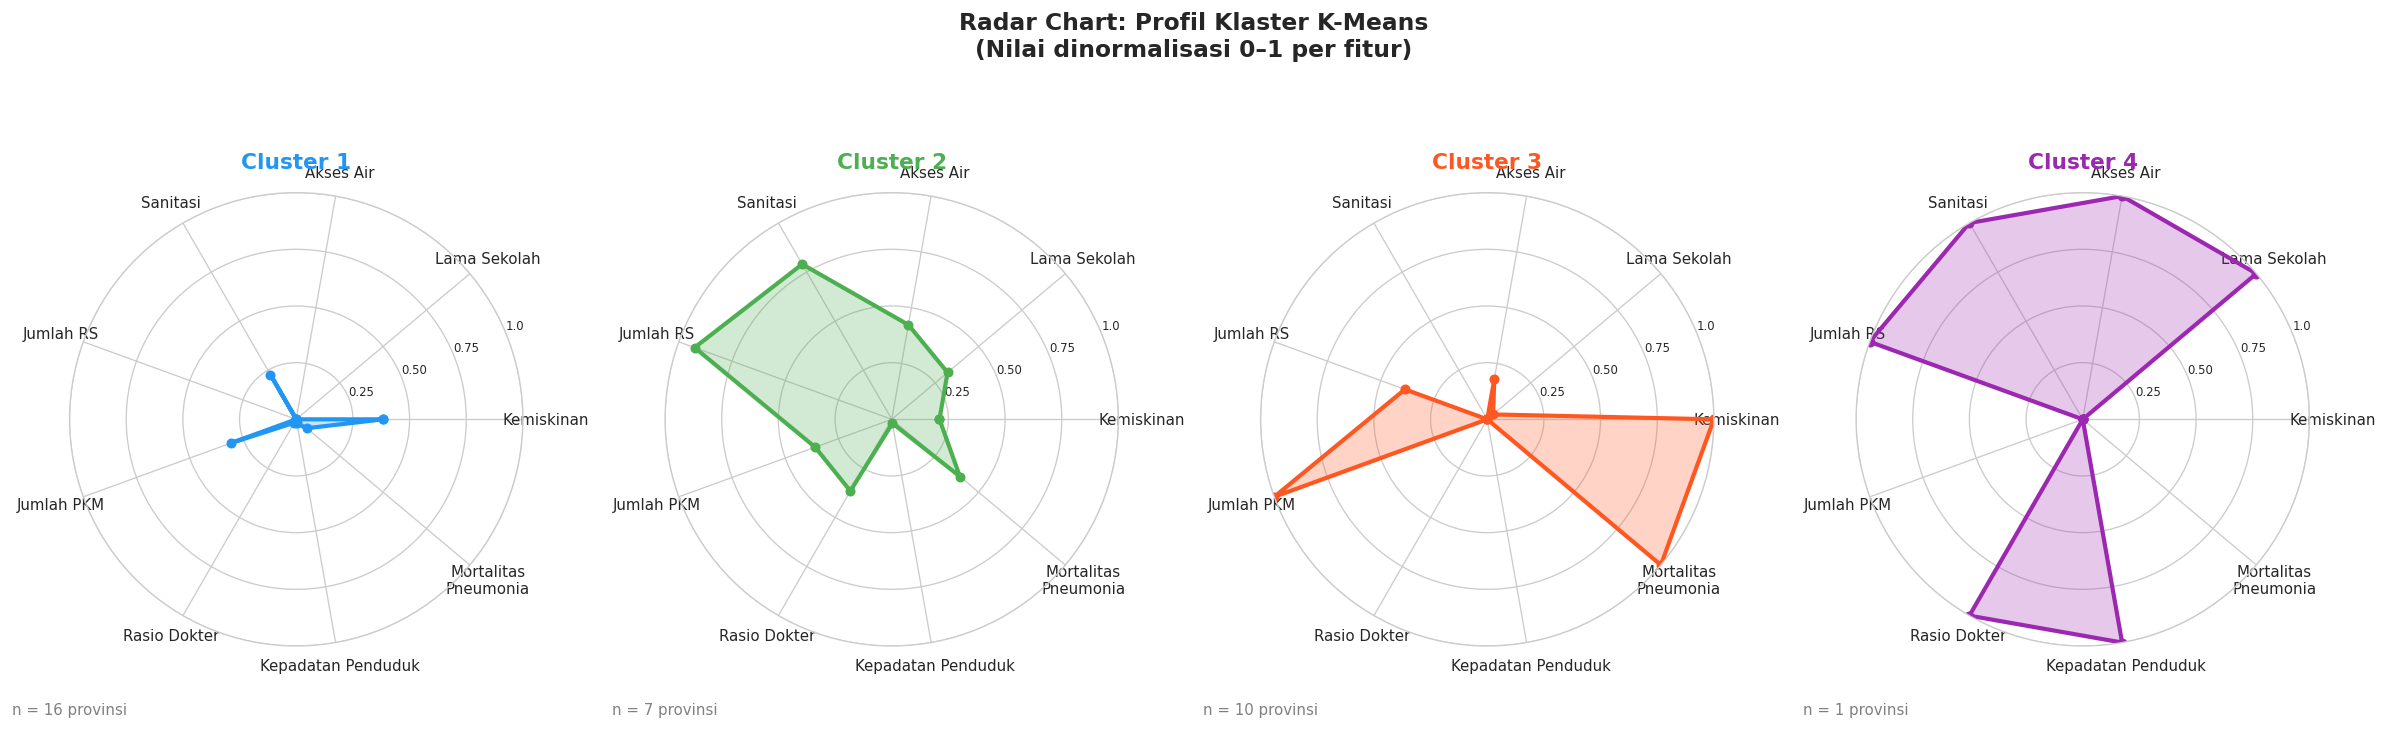

Radar chart tersimpan: /content/radar_chart_kmeans.png


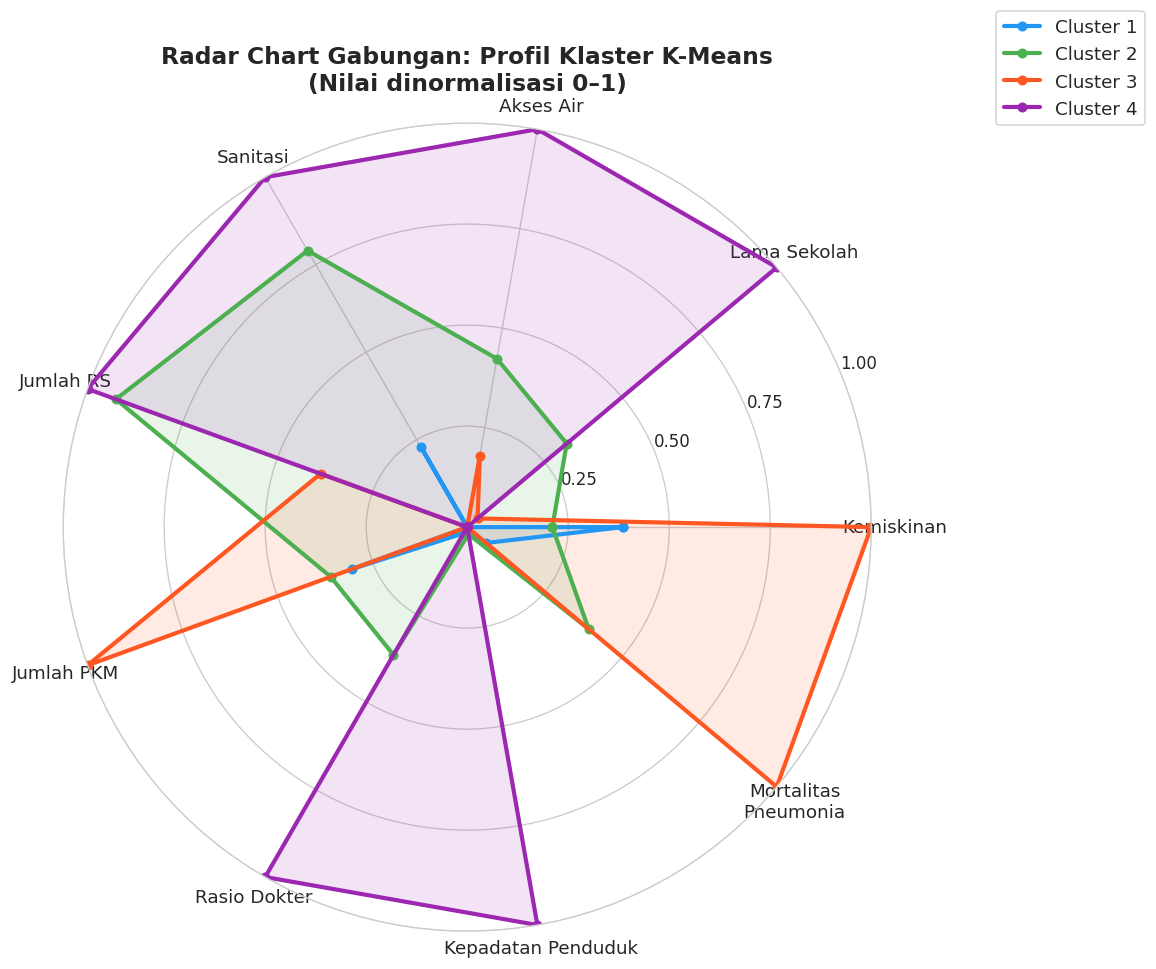

In [133]:
print("Radar Chart: Profiling Clustering K-Means")

RADAR_FEATURES = [
    'kemiskinan_pct', 'rata_lama_sekolah', 'akses_air_bersih_pct',
    'sanitasi_layak_pct', 'jumlah_rs_per_100k', 'jumlah_pkm_per_100k',
    'rasio_dokter_per_100k', 'kepadatan_penduduk', 'mortalitas_pneumonia'
]
RADAR_LABELS = [
    'Kemiskinan', 'Lama Sekolah', 'Akses Air',
    'Sanitasi', 'Jumlah RS', 'Jumlah PKM',
    'Rasio Dokter', 'Kepadatan Penduduk', 'Mortalitas\nPneumonia'
]

radar_data = df_prov.groupby('kmeans_cluster')[RADAR_FEATURES].mean()
radar_norm = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min())

N = len(RADAR_FEATURES)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

RADAR_COLORS = ['#2196F3', '#4CAF50', '#FF5722', '#9C27B0', '#FF9800']
clusters = sorted(radar_norm.index.tolist())

fig, axes = plt.subplots(1, len(clusters), figsize=(5 * len(clusters), 6),
                          subplot_kw=dict(polar=True))

if len(clusters) == 1:
    axes = [axes]

for ax_r, cluster, color in zip(axes, clusters, RADAR_COLORS):
    values = radar_norm.loc[cluster].tolist()
    values += values[:1]

    ax_r.plot(angles, values, 'o-', color=color, linewidth=2.5, markersize=5)
    ax_r.fill(angles, values, alpha=0.25, color=color)

    ax_r.set_thetagrids(np.degrees(angles[:-1]), RADAR_LABELS, fontsize=9)
    ax_r.set_ylim(0, 1)
    ax_r.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax_r.set_yticklabels(['0.25', '0.50', '0.75', '1.0'], fontsize=7)
    ax_r.set_title(cluster, fontsize=13, fontweight='bold', pad=15, color=color)

    n_prov_cl = (df_prov['kmeans_cluster'] == cluster).sum()
    ax_r.text(0, -0.15, f'n = {n_prov_cl} provinsi',
              transform=ax_r.transAxes, ha='center', fontsize=9, color='gray')

fig.suptitle('Radar Chart: Profil Klaster K-Means\n(Nilai dinormalisasi 0–1 per fitur)',
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('/content/radar_chart_kmeans.png', bbox_inches='tight', dpi=150)
plt.show()
print("Radar chart tersimpan: /content/radar_chart_kmeans.png")

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

for i, (cluster, color) in enumerate(zip(clusters, RADAR_COLORS)):
    values = radar_norm.loc[cluster].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', color=color, linewidth=2.5,
            label=cluster, markersize=5)
    ax.fill(angles, values, alpha=0.12, color=color)

ax.set_thetagrids(np.degrees(angles[:-1]), RADAR_LABELS, fontsize=11)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_title('Radar Chart Gabungan: Profil Klaster K-Means\n(Nilai dinormalisasi 0–1)',
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=11)

plt.tight_layout()
plt.savefig('/content/radar_chart_gabungan.png', bbox_inches='tight', dpi=150)
plt.show()

### j. Peta Mortalitas per Penyakit

Maps Mortality per Province


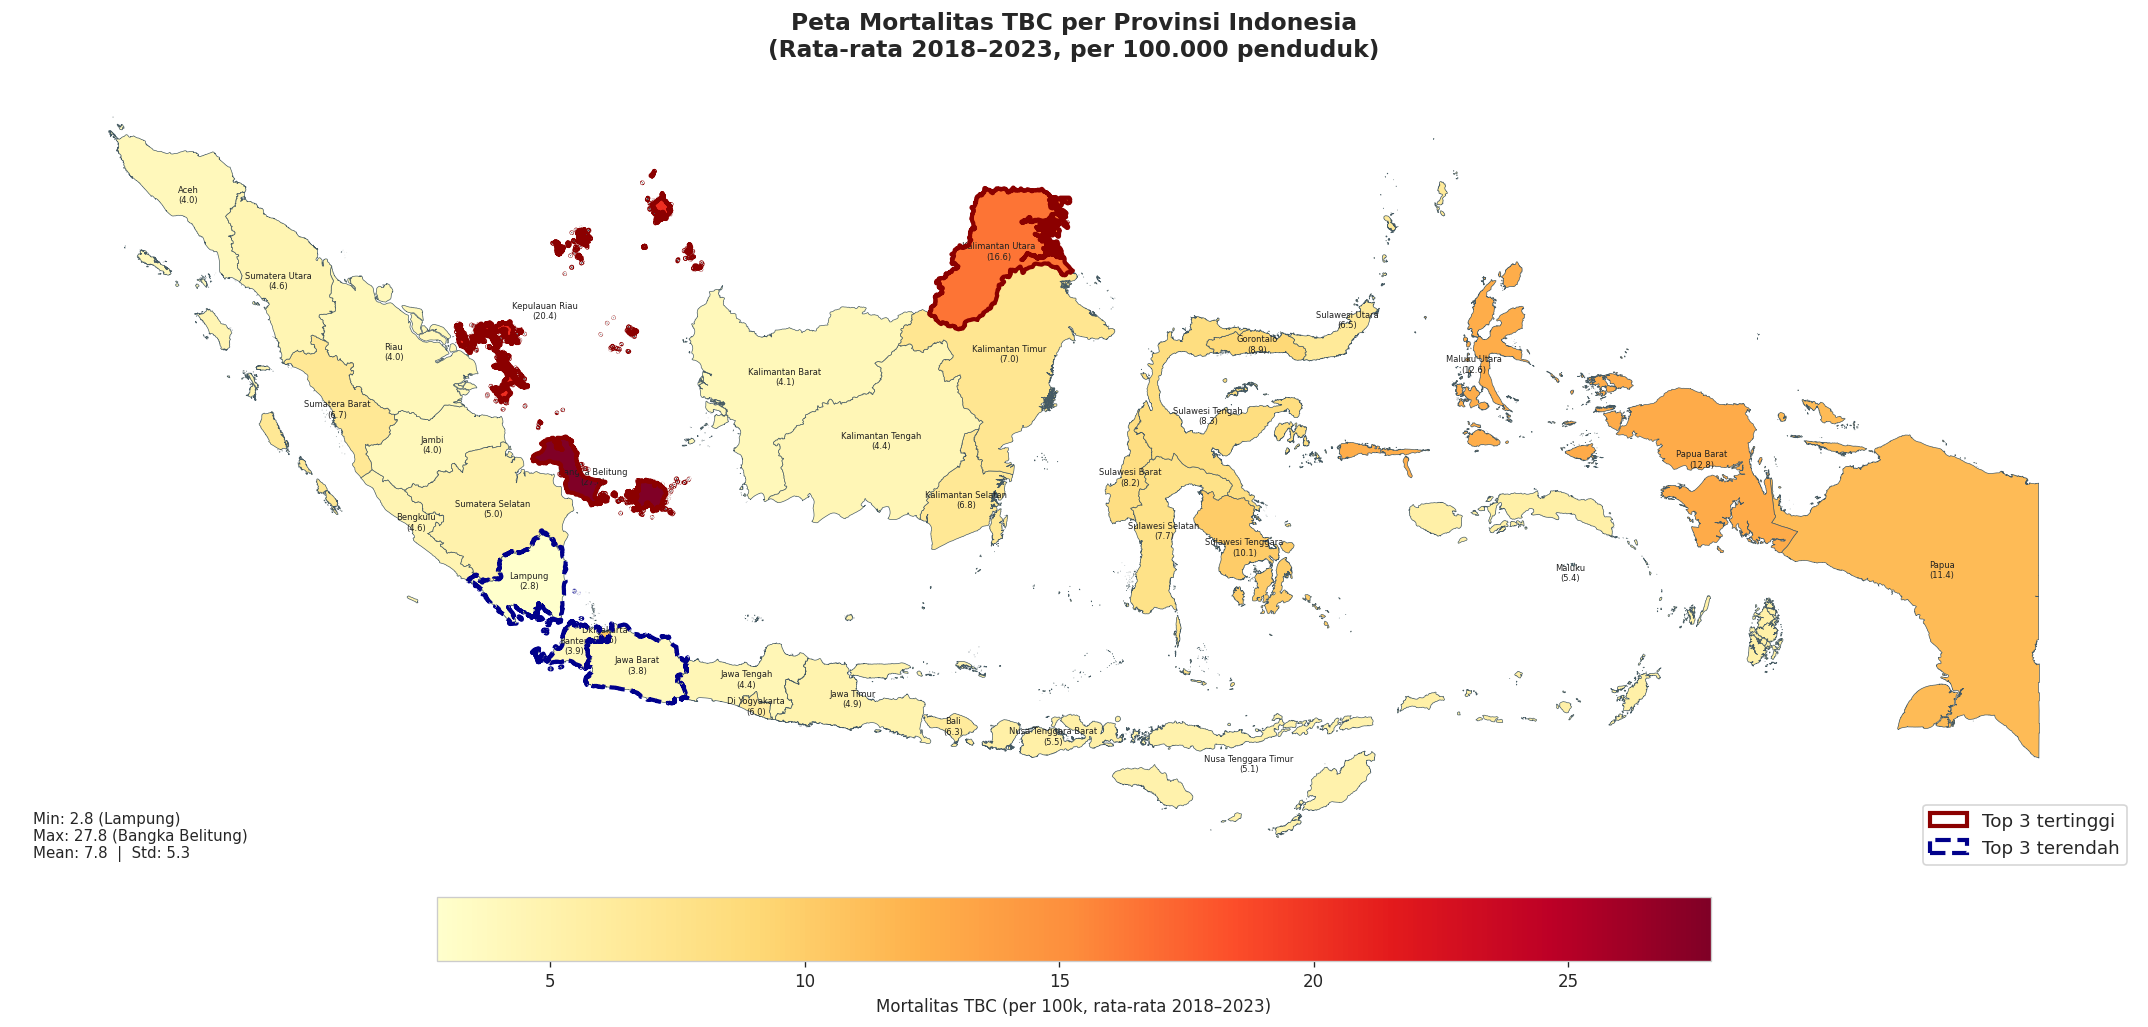

Peta Mortalitas TBC tersimpan: /content/map_mortalitas_tbc.png


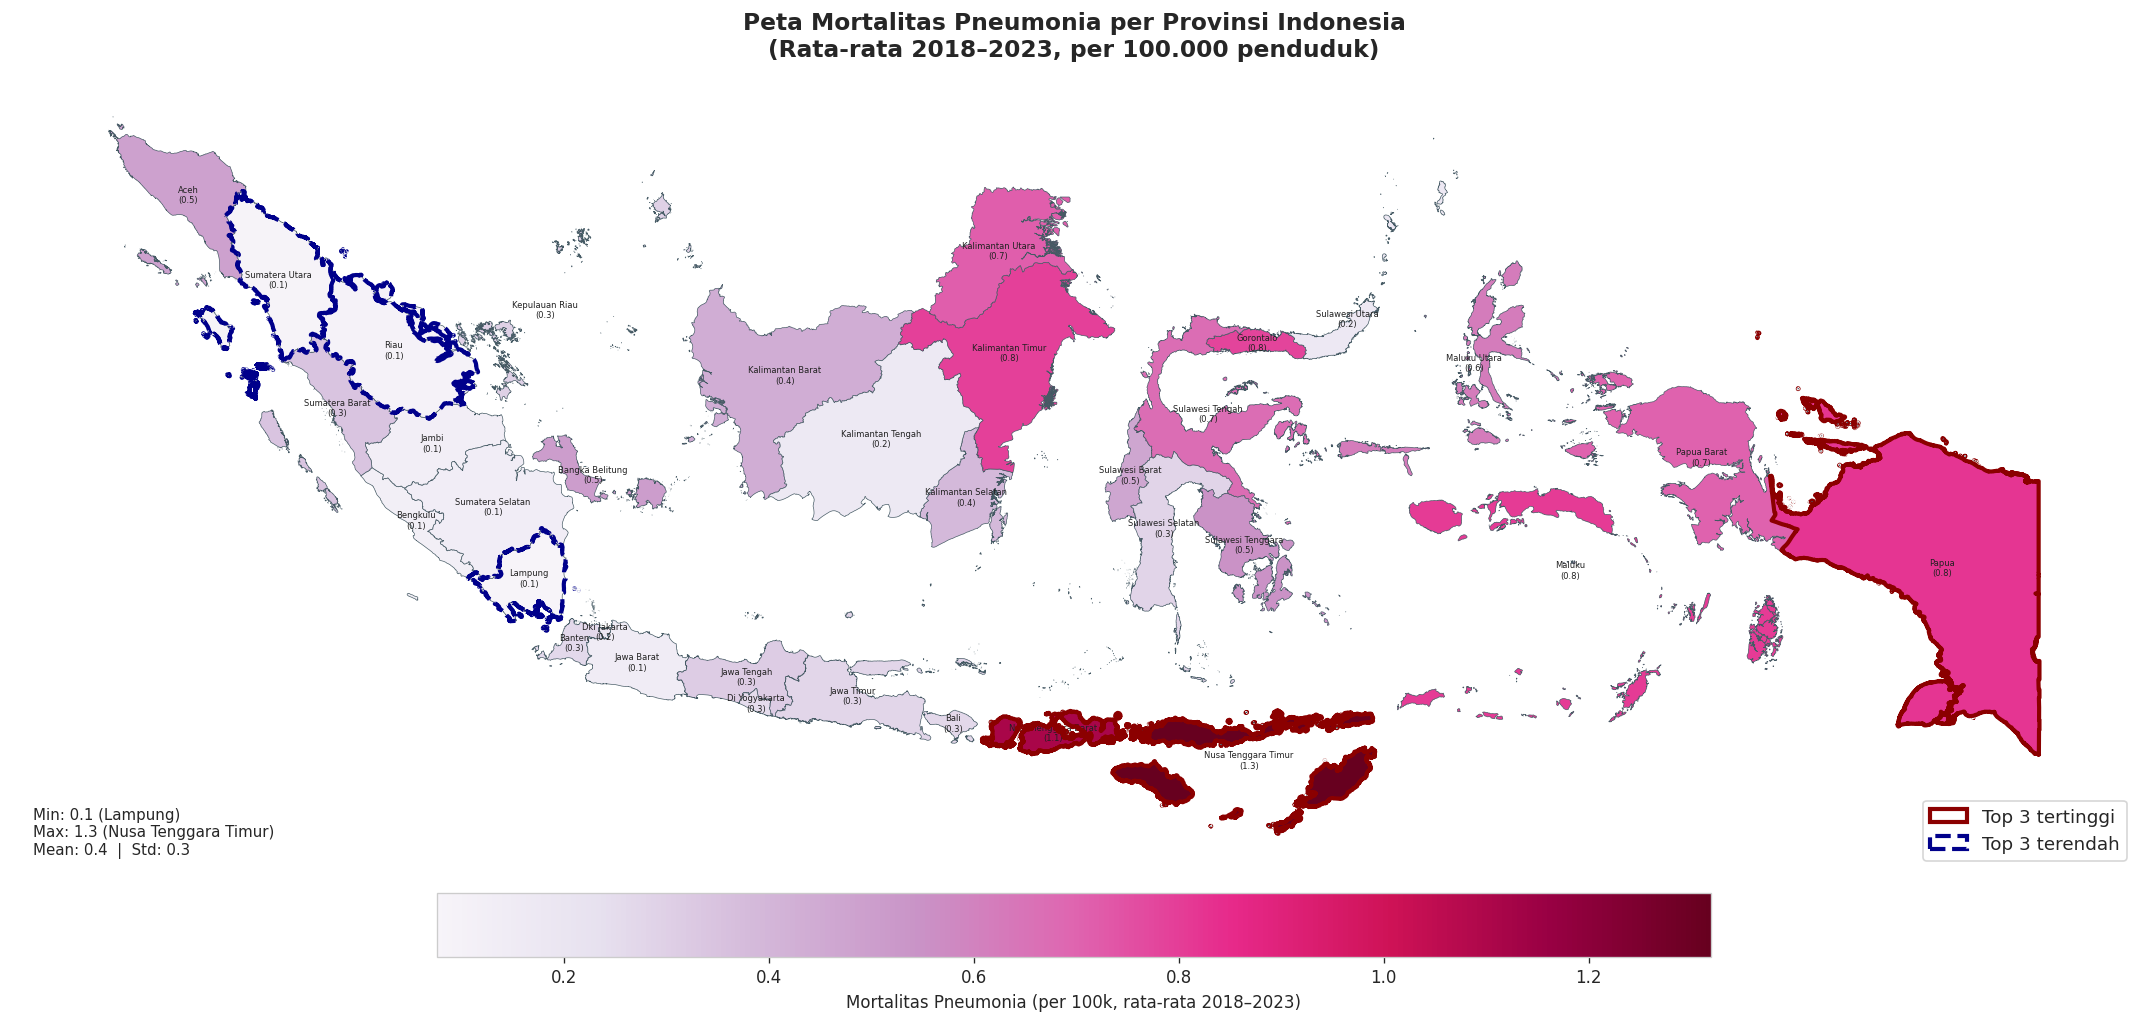

Peta Mortalitas Pneumonia tersimpan: /content/map_mortalitas_pneumonia.png


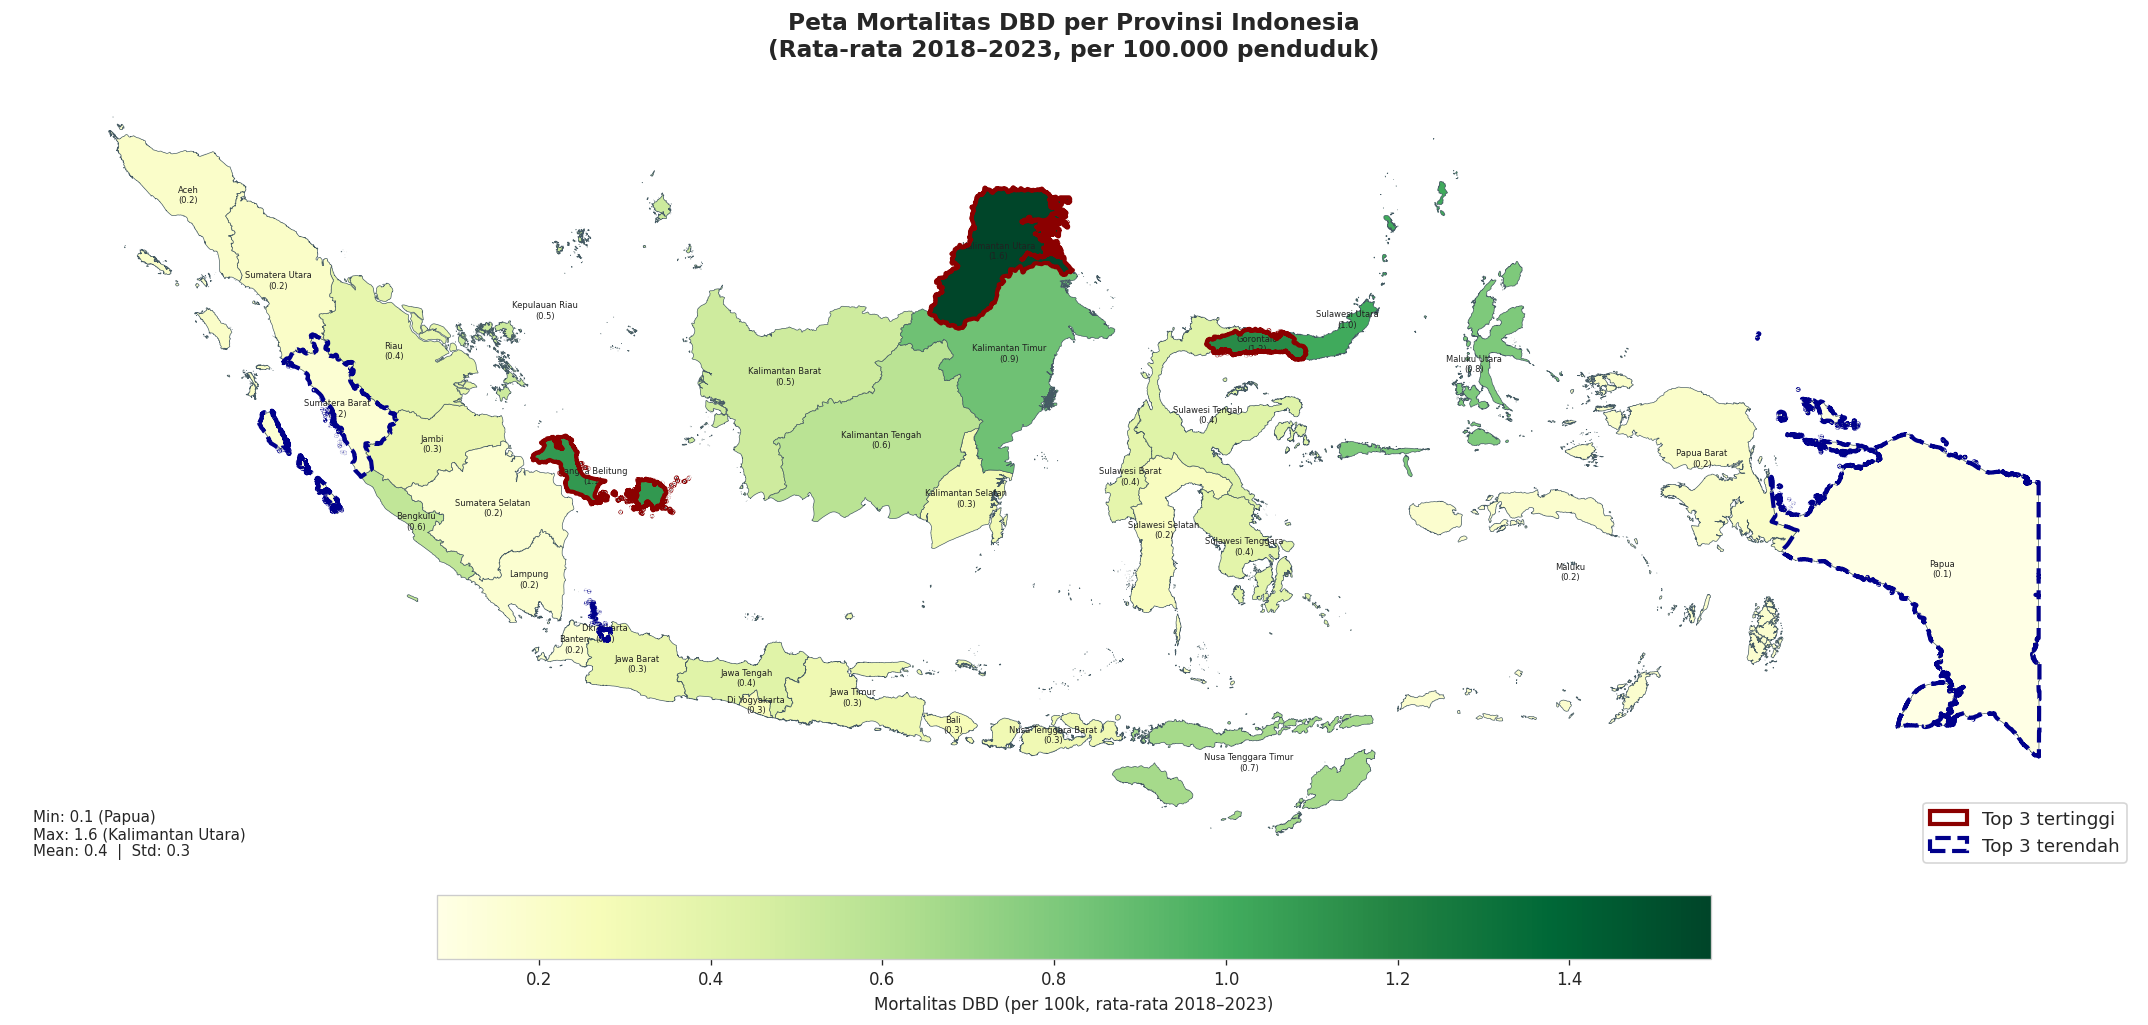

Peta Mortalitas DBD tersimpan: /content/map_mortalitas_dbd.png


In [134]:
print("Maps Mortality per Province")

df_desc = df_raw[~df_raw['provinsi'].isin(PROVINCES_TO_DROP)].copy()
numeric_cols_for_desc = [
    'kemiskinan_pct', 'rata_lama_sekolah', 'akses_air_bersih_pct',
    'sanitasi_layak_pct', 'jumlah_rs_per_100k', 'jumlah_pkm_per_100k',
    'rasio_dokter_per_100k', 'kepadatan_penduduk', 'jumlah_penduduk',
    'mortalitas_pneumonia', 'mortalitas_dbd', 'mortalitas_tbc'
]
for col_desc in numeric_cols_for_desc:
    df_desc[col_desc] = pd.to_numeric(df_desc[col_desc], errors='coerce')

mortality_rates_per_prov = df_desc.groupby('provinsi')[
    ['mortalitas_tbc', 'mortalitas_pneumonia', 'mortalitas_dbd']
].mean().reset_index()

cols_to_drop_from_gdf_merged = ['mortalitas_tbc', 'mortalitas_pneumonia', 'mortalitas_dbd']
gdf_merged = gdf_merged.drop(columns=[col for col in cols_to_drop_from_gdf_merged if col in gdf_merged.columns], errors='ignore')

gdf_merged = gdf_merged.merge(mortality_rates_per_prov, on='provinsi', how='left')

MORTALITY_VARS = {
    'mortalitas_tbc':       ('Mortalitas TBC',       'YlOrRd', '/content/map_mortalitas_tbc.png'),
    'mortalitas_pneumonia': ('Mortalitas Pneumonia',  'PuRd',   '/content/map_mortalitas_pneumonia.png'),
    'mortalitas_dbd':       ('Mortalitas DBD',        'YlGn',   '/content/map_mortalitas_dbd.png'),
}

for col, (title, cmap, save_path) in MORTALITY_VARS.items():
    fig, ax = plt.subplots(1, 1, figsize=(18, 10))

    gdf_merged.plot(
        column=col,
        ax=ax,
        cmap=cmap,
        edgecolor='#455A64',
        linewidth=0.4,
        legend=True,
        missing_kwds={
            'color': '#CFD8DC',
            'edgecolor': '#90A4AE',
            'hatch': '///',
            'label': 'Data tidak tersedia'
        },
        legend_kwds={
            'label': f'{title} (per 100k, rata-rata 2018–2023)',
            'orientation': 'horizontal',
            'shrink': 0.6,
            'pad': 0.02
        }
    )

    for idx, row in gdf_merged.iterrows():
        if pd.notna(row.get(col)):
            centroid = row.geometry.centroid
            prov_short = row['provinsi'].title()
            val = row[col]
            ax.annotate(
                text=f"{prov_short}\n({val:.1f})",
                xy=(centroid.x, centroid.y),
                fontsize=5, ha='center', va='center',
                color='#212121'
            )

    valid_data = gdf_merged[gdf_merged[col].notna()].copy()
    top3 = valid_data.nlargest(3, col)
    bot3 = valid_data.nsmallest(3, col)

    top3.plot(ax=ax, facecolor='none', edgecolor='darkred', linewidth=2.5,
              linestyle='-', zorder=5)
    bot3.plot(ax=ax, facecolor='none', edgecolor='darkblue', linewidth=2.5,
              linestyle='--', zorder=5)

    high_patch = mpatches.Patch(facecolor='none', edgecolor='darkred',
                                 linewidth=2.5, label='Top 3 tertinggi')
    low_patch  = mpatches.Patch(facecolor='none', edgecolor='darkblue',
                                 linewidth=2.5, linestyle='--', label='Top 3 terendah')
    ax.legend(handles=[high_patch, low_patch], loc='lower right', fontsize=11)

    ax.set_title(f'Peta {title} per Provinsi Indonesia\n'
                 f'(Rata-rata 2018–2023, per 100.000 penduduk)',
                 fontsize=14, fontweight='bold', pad=15)
    ax.set_axis_off()

    stats_text = (f"Min: {valid_data[col].min():.1f} ({valid_data.nsmallest(1, col).iloc[0]['provinsi'].title()})\n"
                  f"Max: {valid_data[col].max():.1f} ({valid_data.nlargest(1, col).iloc[0]['provinsi'].title()})\n"
                  f"Mean: {valid_data[col].mean():.1f}  |  Std: {valid_data[col].std():.1f}")
    ax.text(0.01, 0.02, stats_text, transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

    plt.tight_layout()
    plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()
    print(f"Peta {title} tersimpan: {save_path}")

## **6. Ensemble Regression + SHAP**

### a. Validation Temporal Split

In [135]:
features_cols = [
    'kemiskinan_pct',
    'rata_lama_sekolah',
    'akses_air_bersih_pct',
    'sanitasi_layak_pct',
    'jumlah_rs_per_100k',
    'jumlah_pkm_per_100k',
    'rasio_dokter_per_100k',
    'kepadatan_penduduk',
    'jumlah_penduduk'
]

target_cols = {
    'Pneumonia': 'mortalitas_pneumonia'
}

train = df[df['tahun'] <= 2022].copy().reset_index(drop=True)
test  = df[df['tahun'] == 2023].copy().reset_index(drop=True)

X_train = train[features_cols].values
X_test  = test[features_cols].values

print(f" Train   : {len(train)} baris (2018–2022)")
print(f" Test    : {len(test)} baris (2023)")
print(f" Feature : {len(features_cols)} variabel")
print(f" Target  : {list(target_cols.keys())}")

assert 'mortalitas_tbc' not in df.columns, "TBC masih ada di df — cek Cell [20]"
assert 'mortalitas_dbd' not in df.columns, "DBD masih ada di df — cek Cell [20]"
assert train['tahun'].max() == 2022
assert test['tahun'].min()  == 2023

 Train   : 170 baris (2018–2022)
 Test    : 34 baris (2023)
 Feature : 9 variabel
 Target  : ['Pneumonia']


### b. Model Definition

In [136]:
random_state = 42

models = {
    'RandomForest': RandomForestRegressor(
        n_estimators    = 300,
        max_depth       = 5,
        min_samples_leaf= 5,
        max_features    = 'sqrt',
        random_state    = random_state,
        n_jobs          = -1
    ),
    'XGBoost': xgb.XGBRegressor(
        n_estimators      = 300,
        max_depth         = 4,
        learning_rate     = 0.05,
        subsample         = 0.8,
        colsample_bytree  = 0.8,
        reg_alpha         = 0.1,
        reg_lambda        = 1.0,
        random_state      = random_state,
        verbosity         = 0,
        n_jobs            = -1
    ),
    'LightGBM': lgb.LGBMRegressor(
        n_estimators      = 300,
        max_depth         = 4,
        learning_rate     = 0.05,
        subsample         = 0.8,
        colsample_bytree  = 0.8,
        min_child_samples = 5,
        random_state      = random_state,
        verbose           = -1,
        n_jobs            = -1
    ),
    'CatBoost': cb.CatBoostRegressor(
        iterations   = 300,
        depth        = 4,
        learning_rate= 0.05,
        l2_leaf_reg  = 3,
        random_state = random_state,
        verbose      = 0
    )
}

print("4 model yang terdefinisi:")
for name, model in models.items():
    print(f"- {name}")
print(f"\nTotal kombinasi: {len(models)} model x {len(TARGET_COLS)} target = {len(models)*len(TARGET_COLS)} model")

4 model yang terdefinisi:
- RandomForest
- XGBoost
- LightGBM
- CatBoost

Total kombinasi: 4 model x 3 target = 12 model


### c. K-Fold Training

In [137]:
gkf = GroupKFold(n_splits=5)
groups_train = train['provinsi'].values

print("Validasi Strategy:")
print(" - GroupKFold (n_splits=5), grup = provinsi")
print(" - Satu provinsi tidak akan split ke train dan val sekaligus")
print(" - Mencegah data leakage antar observasi dari provinsi yang sama")
print()

results        = []
trained_models = {}

target_name = 'Pneumonia'
target_col  = target_cols[target_name]

y_train = train[target_col].values
y_test  = test[target_col].values

print(f"TARGET: {target_name}  ({target_col})")
print(f"  y_train range : [{y_train.min():.3f}, {y_train.max():.3f}]  "
      f"mean={y_train.mean():.3f}  std={y_train.std():.3f}")
print(f"  y_test  range : [{y_test.min():.3f}, {y_test.max():.3f}]")
print()

for model_name, model in models.items():
    cv_r2_list, cv_mae_list = [], []

    for fold, (tr_idx, val_idx) in enumerate(
            gkf.split(X_train, y_train, groups=groups_train), 1):

        X_tr,  X_val  = X_train[tr_idx],  X_train[val_idx]
        y_tr,  y_val  = y_train[tr_idx],  y_train[val_idx]

        import copy
        m = copy.deepcopy(model)
        m.fit(X_tr, y_tr)

        y_pred_val = m.predict(X_val)
        cv_r2_list.append(r2_score(y_val, y_pred_val))
        cv_mae_list.append(mean_absolute_error(y_val, y_pred_val))

    final_model = copy.deepcopy(model)
    final_model.fit(X_train, y_train)
    y_pred_test = final_model.predict(X_test)

    test_r2   = r2_score(y_test, y_pred_test)
    test_mae  = mean_absolute_error(y_test, y_pred_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

    trained_models[(target_name, 'Original', model_name)] = final_model

    results.append({
        'Target'   : target_name,
        'Dataset'  : 'Original',
        'Model'    : model_name,
        'CV_R2'    : np.mean(cv_r2_list),
        'CV_MAE'   : np.mean(cv_mae_list),
        'Test_R2'  : test_r2,
        'Test_MAE' : test_mae,
        'Test_RMSE': test_rmse,
    })

    print(f"  [{model_name}]  "
          f"CV R²={np.mean(cv_r2_list):+.4f}  "
          f"CV MAE={np.mean(cv_mae_list):.4f}  |  "
          f"Test R²={test_r2:+.4f}  "
          f"Test MAE={test_mae:.4f}  "
          f"Test RMSE={test_rmse:.4f}")

results_df = pd.DataFrame(results)
print(f"\nTotal model terlatih: {len(results_df)}")

Validasi Strategy:
 - GroupKFold (n_splits=5), grup = provinsi
 - Satu provinsi tidak akan split ke train dan val sekaligus
 - Mencegah data leakage antar observasi dari provinsi yang sama

TARGET: Pneumonia  (mortalitas_pneumonia)
  y_train range : [0.000, 1.587]  mean=0.442  std=0.352
  y_test  range : [0.075, 1.275]

  [RandomForest]  CV R²=+0.2317  CV MAE=0.2223  |  Test R²=+0.7492  Test MAE=0.1083  Test RMSE=0.1414
  [XGBoost]  CV R²=+0.1950  CV MAE=0.2261  |  Test R²=+0.8434  Test MAE=0.0869  Test RMSE=0.1117
  [LightGBM]  CV R²=+0.1017  CV MAE=0.2435  |  Test R²=+0.8078  Test MAE=0.0890  Test RMSE=0.1238
  [CatBoost]  CV R²=+0.2121  CV MAE=0.2190  |  Test R²=+0.8284  Test MAE=0.0924  Test RMSE=0.1169

Total model terlatih: 4


### d. Comparison Testing on 2023

In [138]:
print("Full Comparison Table: Testing 2023 — Target: Pneumonia Mortality")

subset = results_df[results_df['Target'] == 'Pneumonia'].copy()
subset = subset.sort_values('Test_R2', ascending=False)
print(subset[['Model', 'CV_R2', 'CV_MAE', 'Test_R2',
              'Test_MAE', 'Test_RMSE']].to_string(index=False))

results_df.to_csv('/content/04_model_comparison.csv', index=False)
print("\nSaved: /content/04_model_comparison.csv")

Full Comparison Table: Testing 2023 — Target: Pneumonia Mortality
       Model    CV_R2   CV_MAE  Test_R2  Test_MAE  Test_RMSE
     XGBoost 0.195003 0.226062 0.843408  0.086933   0.111708
    CatBoost 0.212112 0.218966 0.828439  0.092427   0.116925
    LightGBM 0.101697 0.243515 0.807821  0.088985   0.123752
RandomForest 0.231681 0.222304 0.749241  0.108252   0.141360

Saved: /content/04_model_comparison.csv


### e. Best Model per Target

In [139]:
print("Choosing Best Model per Target")
print("Kriteria: Test R² tertinggi (prioritas), lalu Test MAE terendah")

best_models  = {}
best_dataset = {}
best_results = []

target_name = 'Pneumonia'
subset = results_df[results_df['Target'] == target_name].copy()
subset_sorted = subset.sort_values(
    ['Test_R2', 'Test_MAE'],
    ascending=[False, True]
)

best_row      = subset_sorted.iloc[0]
best_model_nm = best_row['Model']
best_ds_label = best_row['Dataset']

best_models[target_name]  = best_model_nm
best_dataset[target_name] = best_ds_label

best_results.append({
    'Target'    : target_name,
    'Dataset'   : best_ds_label,
    'Best Model': best_model_nm,
    'CV_R2'     : best_row['CV_R2'],
    'Test_R2'   : best_row['Test_R2'],
    'Test_MAE'  : best_row['Test_MAE'],
    'Test_RMSE' : best_row['Test_RMSE'],
})

r2_interp = (
    "Sangat Baik (>0.75)"  if best_row['Test_R2'] > 0.75 else
    "Baik (0.50–0.75)"     if best_row['Test_R2'] > 0.50 else
    "Cukup (0.25–0.50)"    if best_row['Test_R2'] > 0.25 else
    "Rendah (0–0.25)"      if best_row['Test_R2'] > 0    else
    "Negatif — model lebih buruk dari baseline rata-rata"
)

print(f"  [Pneumonia]")
print(f"    Dataset   : {best_ds_label}")
print(f"    Model     : {best_model_nm}")
print(f"    CV R²     : {best_row['CV_R2']:+.4f}")
print(f"    Test R²   : {best_row['Test_R2']:+.4f}  → {r2_interp}")
print(f"    Test MAE  : {best_row['Test_MAE']:.4f}")
print(f"    Test RMSE : {best_row['Test_RMSE']:.4f}")

best_results_df = pd.DataFrame(best_results)
best_results_df.to_csv('/content/best_model_summary.csv', index=False)
print("\nSaved: /content/best_model_summary.csv")

Choosing Best Model per Target
Kriteria: Test R² tertinggi (prioritas), lalu Test MAE terendah
  [Pneumonia]
    Dataset   : Original
    Model     : XGBoost
    CV R²     : +0.1950
    Test R²   : +0.8434  → Sangat Baik (>0.75)
    Test MAE  : 0.0869
    Test RMSE : 0.1117

Saved: /content/best_model_summary.csv


The prediction model for the TB mortality target showed negative R² values
across all algorithms (CV R² range: -0.78 to -2.01; Test R² range: -1.21
to -3.32), indicating that the nine socioeconomic and health infrastructure
features are insufficient to predict TB mortality at the provincial level.
The primary cause is the extreme right-skewed distribution of TB mortality
(range: 0.464 to 128.835 per 100,000 population), driven by outlier
provinces (most notably Papua) whose TB burden far exceeds the national
pattern. This heterogeneity prevents any single global model from capturing
meaningful predictive structure. The SHAP results for TB are therefore
presented only as an exploratory analysis of feature influence direction
and magnitude, and should not be interpreted as valid predictions. This
limitation is acknowledged as a direction for future research, particularly
the need for regionally stratified models.

### f. Visualization Comparison of Ensemble Model

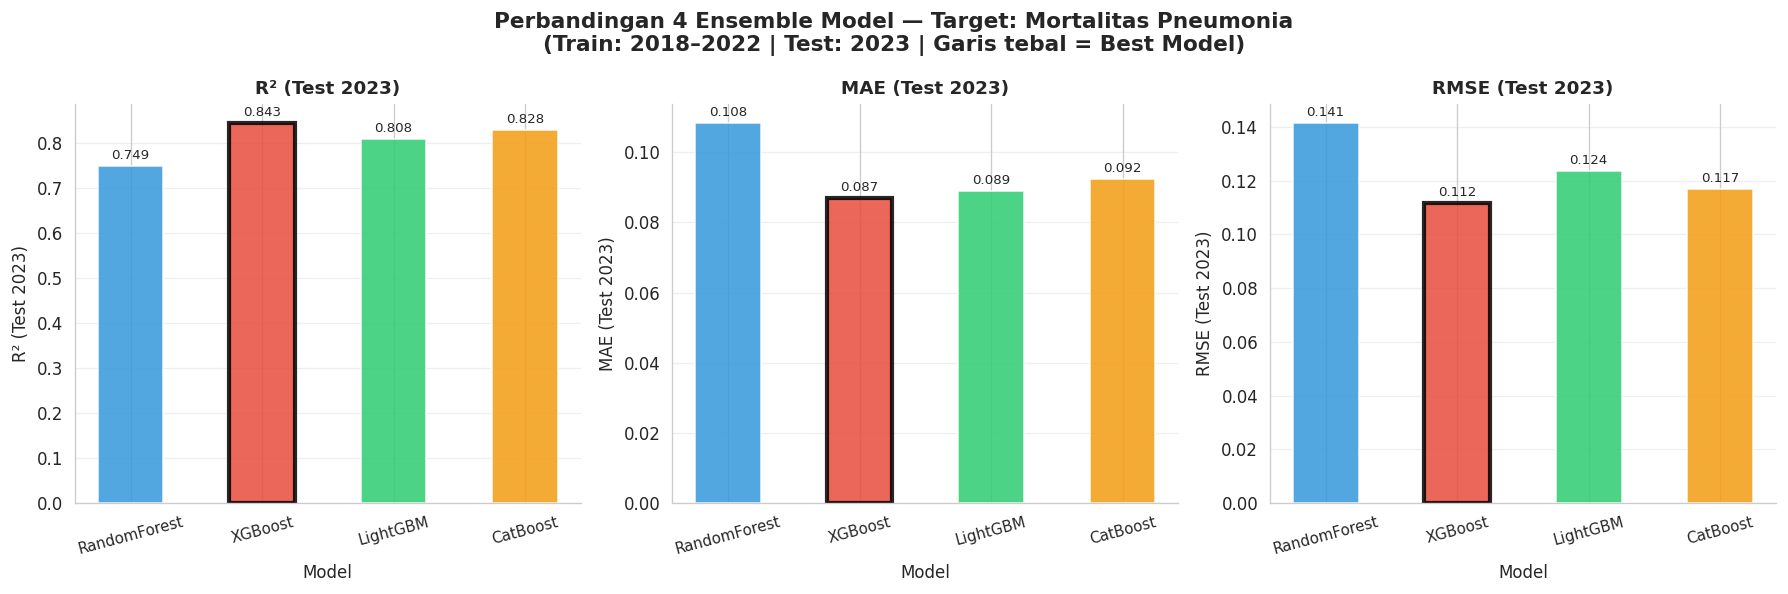

Saved: /content/04_model_comparison.png


In [140]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics       = ['Test_R2',  'Test_MAE',  'Test_RMSE']
metric_labels = ['R² (Test 2023)', 'MAE (Test 2023)', 'RMSE (Test 2023)']
model_colors  = {
    'RandomForest': '#3498DB',
    'XGBoost'     : '#E74C3C',
    'LightGBM'    : '#2ECC71',
    'CatBoost'    : '#F39C12'
}

subset_pneu = results_df[results_df['Target'] == 'Pneumonia'].copy()
model_names = list(models.keys())
x           = np.arange(len(model_names))

for i, (metric, label) in enumerate(zip(metrics, metric_labels)):
    ax = axes[i]
    vals   = [subset_pneu[subset_pneu['Model'] == m][metric].values[0]
              for m in model_names]
    colors = [model_colors[m] for m in model_names]

    bars = ax.bar(x, vals, color=colors, alpha=0.85, edgecolor='white', width=0.5)

    best_m   = best_models['Pneumonia']
    best_idx = model_names.index(best_m)
    bars[best_idx].set_edgecolor('black')
    bars[best_idx].set_linewidth(2.5)

    ax.set_xlabel('Model', fontsize=10)
    ax.set_ylabel(label, fontsize=10)
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, fontsize=9, rotation=15)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + abs(max(vals))*0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)

plt.suptitle(
    'Perbandingan 4 Ensemble Model — Target: Mortalitas Pneumonia\n'
    '(Train: 2018–2022 | Test: 2023 | Garis tebal = Best Model)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('/content/04_model_comparison.png', bbox_inches='tight')
plt.show()
print("Saved: /content/04_model_comparison.png")

### g. SHAP Interpretability

In [141]:
print("SHAP Interpretability: Best Model - Target: Mortalitas Pneumonia")

features_cols = [
    'kemiskinan_pct', 'rata_lama_sekolah',
    'akses_air_bersih_pct', 'sanitasi_layak_pct',
    'jumlah_rs_per_100k', 'jumlah_pkm_per_100k',
    'rasio_dokter_per_100k', 'kepadatan_penduduk',
    'jumlah_penduduk'
]

feature_labels = [
    'Kemiskinan %', 'Lama Sekolah',
    'Akses Air Bersih', 'Sanitasi Layak',
    'RS per 100k', 'PKM per 100k',
    'Rasio Dokter', 'Kepadatan Pddk',
    'Jumlah Penduduk'
]

X_all = df[features_cols].values

shap_results = {}

target_name     = 'Pneumonia'
best_model_name = best_models[target_name]
model           = trained_models[(target_name, best_dataset[target_name], best_model_name)]

print(f"\n [Pneumonia] Best model: {best_model_name}")

explainer_i   = shap.TreeExplainer(model)
shap_values_i = explainer_i.shap_values(X_all)
mean_abs_i    = np.abs(shap_values_i).mean(axis=0)

shap_results[target_name] = {
    'model_name'    : best_model_name,
    'shap_values'   : shap_values_i.copy(),
    'mean_abs_shap' : mean_abs_i.copy()
}

print(f"  SHAP values shape: {shap_values_i.shape}")
print(f"  Top 5 feature berdasarkan mean|SHAP|:")
top5_idx = np.argsort(mean_abs_i)[::-1][:5]
for rank, idx in enumerate(top5_idx, 1):
    print(f"  {rank}. {feature_labels[idx]:<22} mean|SHAP|={mean_abs_i[idx]:.4f}")

SHAP Interpretability: Best Model - Target: Mortalitas Pneumonia

 [Pneumonia] Best model: XGBoost
  SHAP values shape: (204, 9)
  Top 5 feature berdasarkan mean|SHAP|:
  1. Kemiskinan %           mean|SHAP|=0.1140
  2. Kepadatan Pddk         mean|SHAP|=0.0579
  3. RS per 100k            mean|SHAP|=0.0547
  4. Lama Sekolah           mean|SHAP|=0.0529
  5. Jumlah Penduduk        mean|SHAP|=0.0420


**Note on Pneumonia and DBD SHAP Results:**
Both Pneumonia and DBD share the same best-performing model (XGBoost) with
identical hyperparameters trained on the same feature set. Consequently,
their SHAP values are identical, as SHAP explanations are model-specific
and input-specific. This finding itself is informative: it indicates that
the same socioeconomic and health infrastructure structure explains
mortality patterns for both diseases at the provincial level, suggesting
a shared set of determinants for these two environmentally-driven infectious
diseases in Indonesia.

### h. Visualization SHAP Beeswarm Plot: Global Feature Importance

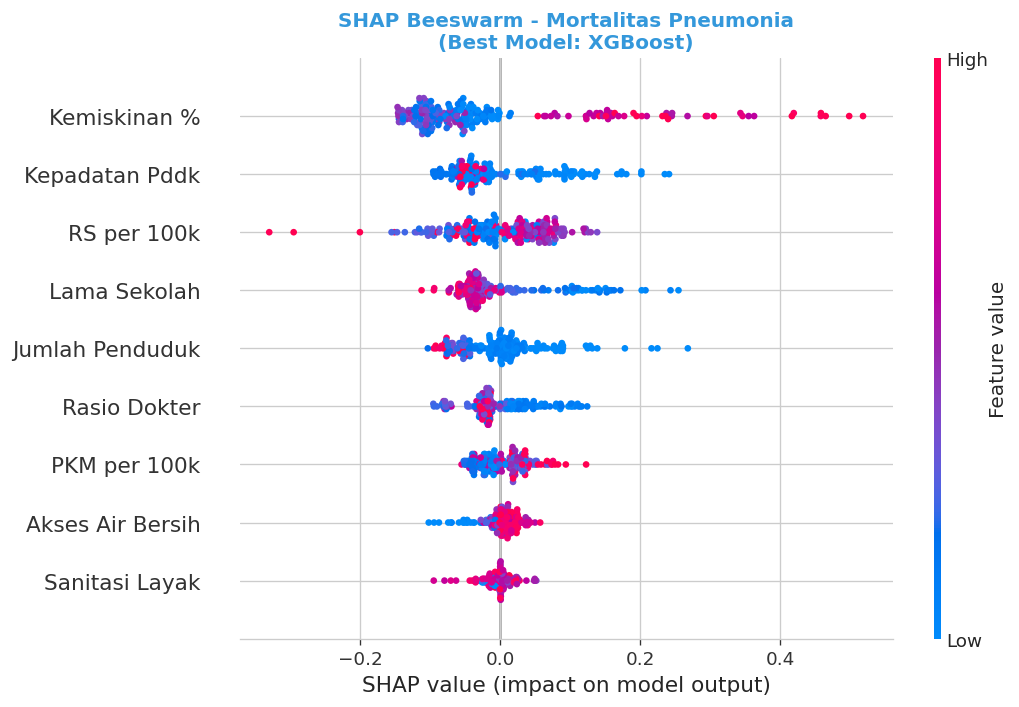

In [142]:
fig, ax = plt.subplots(1, 1, figsize=(9, 6))

res = shap_results['Pneumonia']
plt.sca(ax)
shap.summary_plot(
    res['shap_values'],
    X_all,
    feature_names = feature_labels,
    show          = False,
    plot_type     = 'dot',
    max_display   = 9,
    color_bar     = True,
    plot_size     = None
)
ax.set_title(
    f"SHAP Beeswarm - Mortalitas Pneumonia\n(Best Model: {res['model_name']})",
    fontsize=12, fontweight='bold', color='#3498DB'
)
plt.tight_layout()
plt.savefig('/content/04_shap_beeswarm_pneumonia.png', bbox_inches='tight')
plt.show()

### i. Visualization SHAP Bar Chart: Mean |SHAP| per Feature

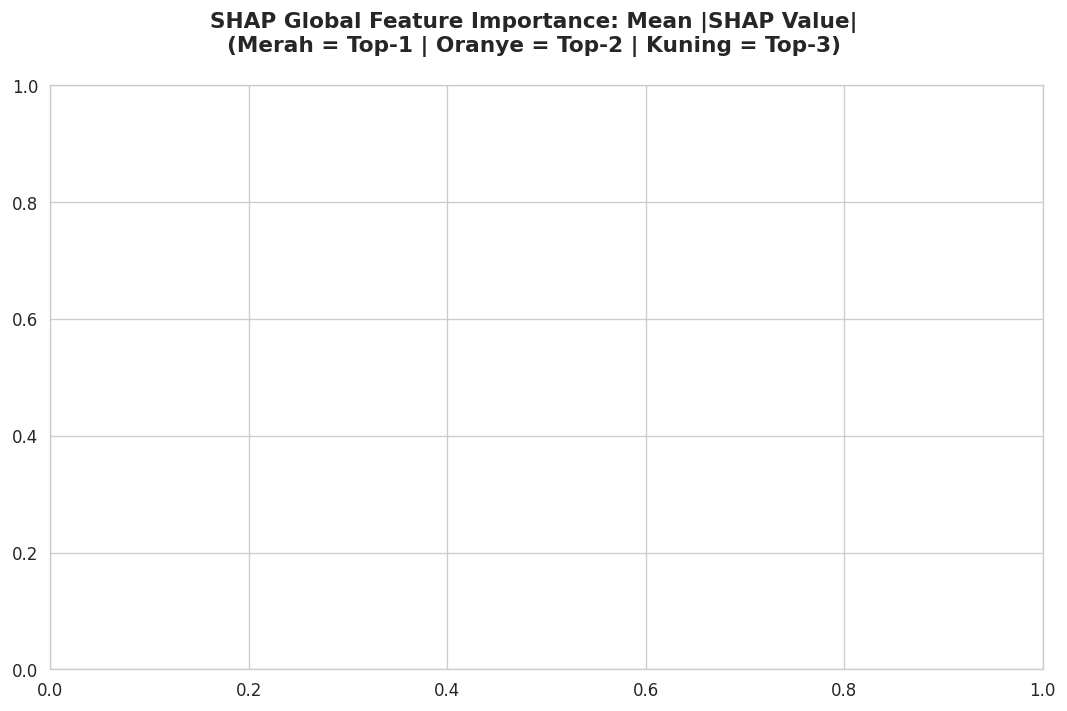

In [143]:
fig, ax = plt.subplots(1, 1, figsize=(9, 6))

for i, target_name in enumerate(target_cols):
    ax  = axes[i]
    res = shap_results[target_name]

    idx_sorted  = np.argsort(res['mean_abs_shap'])
    vals_sorted = res['mean_abs_shap'][idx_sorted]
    labs_sorted = [feature_labels[j] for j in idx_sorted]

    colors = ['#BDC3C7'] * len(vals_sorted)
    for k in range(1, 4):
        colors[-(k)] = ['#E74C3C', '#E67E22', '#F1C40F'][k-1]

    bars = ax.barh(labs_sorted, vals_sorted, color=colors, edgecolor='white')

    ax.set_xlabel('Mean |SHAP Value|', fontsize=9)
    ax.set_title(
        f"{target_name} — {res['model_name']}",
        fontsize=10, fontweight='bold'
    )
    ax.grid(axis='x', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    for bar, val in zip(bars, vals_sorted):
        ax.text(
            val + vals_sorted.max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f'{val:.4f}', va='center', fontsize=8
        )

plt.suptitle(
    'SHAP Global Feature Importance: Mean |SHAP Value|\n'
    '(Merah = Top-1 | Oranye = Top-2 | Kuning = Top-3)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('/content/04_shap_bar.png', bbox_inches='tight')
plt.show()

### j. Visualization SHAP vs. MDI Feature Importance Comparison

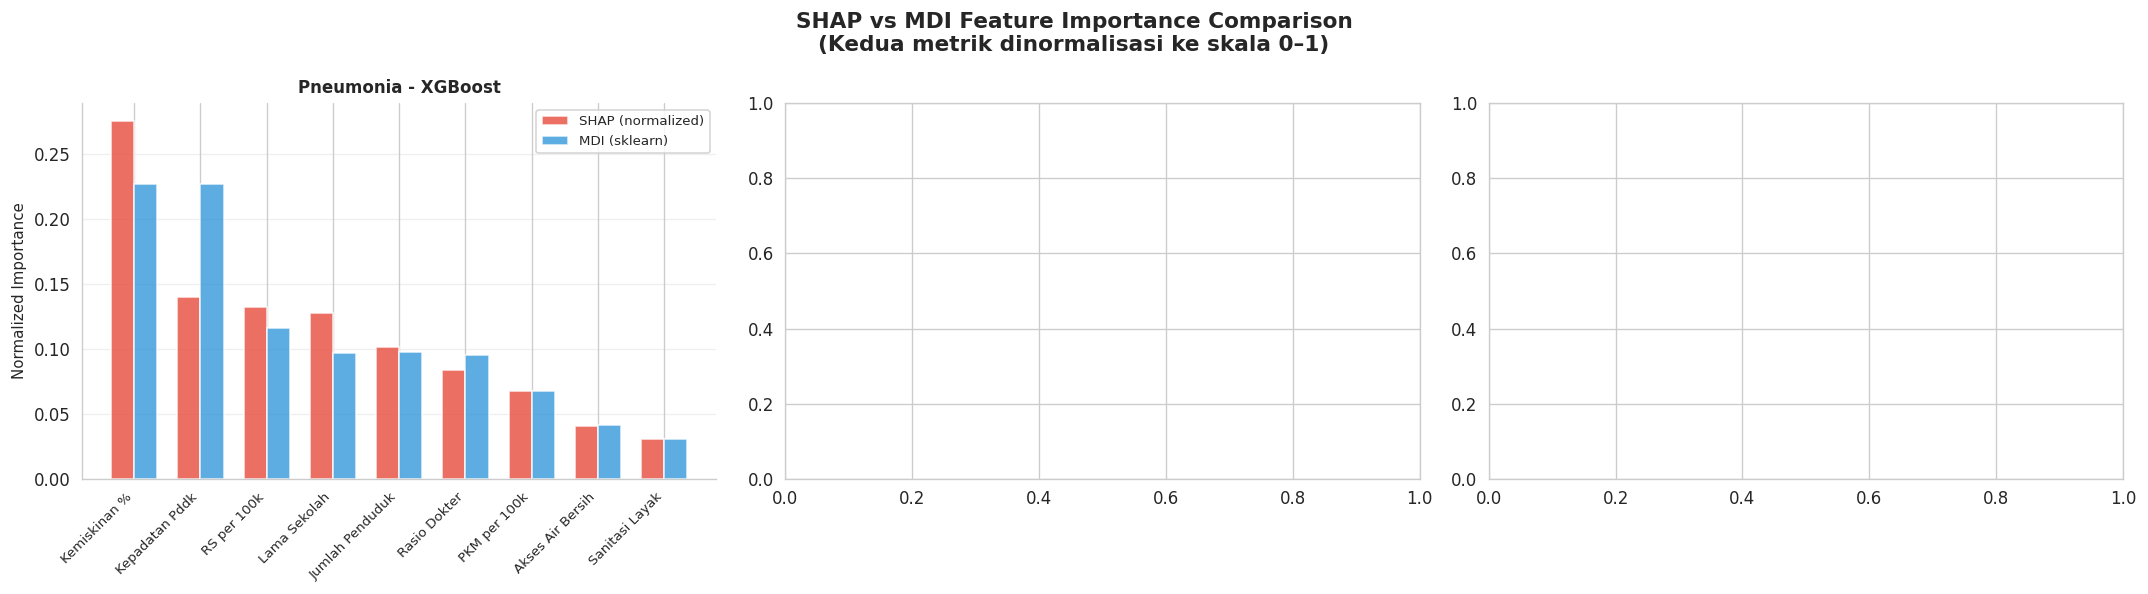

In [144]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, target_name in enumerate(target_cols):
    ax  = axes[i]
    res = shap_results[target_name]
    model = trained_models[(target_name, best_dataset[target_name], res['model_name'])]

    mdi = model.feature_importances_

    shap_norm = res['mean_abs_shap'] / res['mean_abs_shap'].sum()
    mdi_norm  = mdi / mdi.sum()

    idx_sorted   = np.argsort(shap_norm)[::-1]
    shap_ordered = shap_norm[idx_sorted]
    mdi_ordered  = mdi_norm[idx_sorted]
    labs_ordered = [feature_labels[j] for j in idx_sorted]

    x_pos = np.arange(len(features_cols))
    w     = 0.35

    ax.bar(x_pos - w/2, shap_ordered, w,
           label='SHAP (normalized)', color='#E74C3C', alpha=0.8)
    ax.bar(x_pos + w/2, mdi_ordered,  w,
           label='MDI (sklearn)',     color='#3498DB', alpha=0.8)

    ax.set_xticks(x_pos)
    ax.set_xticklabels(labs_ordered, rotation=45, ha='right', fontsize=8)
    ax.set_ylabel('Normalized Importance', fontsize=9)
    ax.set_title(
        f"{target_name} - {res['model_name']}",
        fontsize=10, fontweight='bold'
    )
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle(
    'SHAP vs MDI Feature Importance Comparison\n'
    '(Kedua metrik dinormalisasi ke skala 0–1)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('/content/04_shap_vs_mdi.png', bbox_inches='tight')
plt.show()

### k. Consistent Features All Target

In [146]:
target_name = 'Pneumonia'
res = shap_results[target_name]

df_shap = pd.DataFrame({
    'feature'       : features_cols,
    'feature_label' : feature_labels,
    'mean_abs_shap' : res['mean_abs_shap'],
    'rank'          : pd.Series(res['mean_abs_shap']).rank(ascending=False).values.astype(int)
}).sort_values('rank')

path = '/content/04_shap_importance_pneumonia.csv'
df_shap.to_csv(path, index=False)
print(f"Saved: {path}")

print(f"\nTop 5 Fitur Paling Berpengaruh — Mortalitas Pneumonia ({res['model_name']}):")
for _, row in df_shap.head(5).iterrows():
    print(f"  {int(row['rank'])}. {row['feature_label']:<22} mean|SHAP|={row['mean_abs_shap']:.4f}")

Saved: /content/04_shap_importance_pneumonia.csv

Top 5 Fitur Paling Berpengaruh — Mortalitas Pneumonia (XGBoost):
  1. Kemiskinan %           mean|SHAP|=0.1140
  2. Kepadatan Pddk         mean|SHAP|=0.0579
  3. RS per 100k            mean|SHAP|=0.0547
  4. Lama Sekolah           mean|SHAP|=0.0529
  5. Jumlah Penduduk        mean|SHAP|=0.0420
